# H15: Single-Cell Analysis
**Clustering, Phenotyping & Genotype Associations**

11 donors · 22 common markers · H14 crop windows

Pipeline: crop filtering → marker harmonization → arcsinh + per-image z-score →
PCA → **Harmony batch correction (Platform)** → Leiden clustering → cell-type gating → genotype / region / distance / neighborhood analyses

In [1]:
import subprocess, sys
for pkg in ['scanpy', 'leidenalg', 'harmonypy']:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

In [2]:
import os
os.environ["NUMBA_NUM_THREADS"] = "64"
os.environ["OMP_NUM_THREADS"] = "64"
os.environ["OPENBLAS_NUM_THREADS"] = "64"

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import anndata as ad
from scipy.spatial import cKDTree
from pathlib import Path

from data_utils import (
    extract_sample_id, GENOTYPE_MAP, CODEX_SAMPLES, EXCLUDE_SAMPLES,
    GENO_ORDER, GENO_PALETTE, MAIN_REGIONS, REGION_ORDER,
    assign_regions_by_image, load_region_layer, signed_distance_by_image,
    full_stats_table, platform_diagnostic, save_figure, save_table,
    setup_style, PROJECT, DATA_CSV,
)

setup_style()

# ---------------------------------------------------------------------------
# Constants
# ---------------------------------------------------------------------------
CELLS_CSV = PROJECT / "Measurements" / "Cells.csv"

# 18 exact-match markers (same column name in both platforms)
COMMON_MARKERS_EXACT = [
    "CD45RO", "Ki67", "CD20", "CD4", "CD44", "CD31", "CD11c", "CD34",
    "CD107a", "CD163", "HLA-DR", "CD68", "CD8", "CD21", "Vimentin",
    "CD3e", "CD45", "Podoplanin",
]

# 4 harmonizable markers: (canonical, phenocycler_col, codex_col)
HARMONIZE = [
    ("FOXP3",      "Cell: FOXP3: Mean",       "Cell: FoxP3: Mean"),
    ("SMA",        "Cell: SMA: Mean",          "Cell: SMActin: Mean"),
    ("CollagenIV", "Cell: Collagen IV: Mean",   "Cell: CollagenIV: Mean"),
    ("Ecadherin",  "Cell: E-cadherin: Mean",    "Cell: ECAD: Mean"),
]

CLUSTERING_MARKERS = COMMON_MARKERS_EXACT + [h[0] for h in HARMONIZE]  # 22
MARKER_COLS_EXACT = [f"Cell: {m}: Mean" for m in COMMON_MARKERS_EXACT]
HARMONIZE_COLS = [col for _, pc, cx in HARMONIZE for col in (pc, cx)]

# Coordinates and metadata columns
X_COL, Y_COL = "Centroid X \u00b5m", "Centroid Y \u00b5m"
DIST_COLS = [
    "Signed distance to annotation Follicle \u00b5m",
    "Signed distance to annotation PALS \u00b5m",
    "Signed distance to annotation RedPulp \u00b5m",
    "Signed distance to annotation SmallVessel \u00b5m",
    "Signed distance to annotation LargeVessel \u00b5m",
    "Signed distance to annotation Trabeculae \u00b5m",
]
META_COLS = ["Image", "Object ID", X_COL, Y_COL, "Cell: Area \u00b5m^2"]
USE_COLS = META_COLS + MARKER_COLS_EXACT + HARMONIZE_COLS + DIST_COLS

# ── Cropping is DISABLED: Phenocycler sections are analysed whole ──
# Cropping them to a CODEX-sized window was a mitigation for the ~10x difference
# in imaged area. It is abandoned. It discarded 75-88% of the data to address
# only the first of the four confound mechanisms — unequal effort — and left
# field selection, optical resolution and detection sensitivity untouched. A
# larger section yields a more precise estimate, not a biased one; H20's
# count-rate model with an area offset is the replacement.
#
# The thresholds are pushed beyond any real extent rather than deleted, so the
# machinery below still runs and returns "no crop" for every sample. That keeps
# the downstream guards exercised rather than leaving dead branches behind.
CROP_W, CROP_H = 5000, 3000
CROP_THRESHOLD_X, CROP_THRESHOLD_Y = np.inf, np.inf
CROP_OVERRIDES = {"HDL011": (2000, 2000)}

# Transform
ARCSINH_COFACTOR = 150

# Neighborhood
SPATIAL_K = 20

# Scanpy verbosity — show info messages to verify pynndescent usage
sc.settings.verbosity = 2

print(f"Markers: {len(CLUSTERING_MARKERS)} ({len(COMMON_MARKERS_EXACT)} exact + {len(HARMONIZE)} harmonized)")
print(f"Columns to load: {len(USE_COLS)}")
print("Cropping: DISABLED (full sections)")
print(f"Thread settings: NUMBA={os.environ['NUMBA_NUM_THREADS']}, OMP={os.environ['OMP_NUM_THREADS']}")

Markers: 22 (18 exact + 4 harmonized)
Columns to load: 37
Crop window: 5000x3000 µm
Thread settings: NUMBA=64, OMP=64


In [3]:
# ── Compute crop windows from AnnotationsFinal.csv (matches H14) ──
annot = pd.read_csv(DATA_CSV, usecols=["Image", X_COL, Y_COL])
annot["Sample"] = annot["Image"].apply(extract_sample_id)
annot = annot[~annot["Sample"].isin(EXCLUDE_SAMPLES)]

half_w, half_h = CROP_W / 2, CROP_H / 2
crop_windows = {}   # sample -> (cx, cy) or None
img_to_sample = {}  # image name -> sample

for sample in sorted(annot["Sample"].unique()):
    sdf = annot[annot["Sample"] == sample]
    # record image -> sample mapping
    for img in sdf["Image"].unique():
        img_to_sample[img] = sample
    coords = sdf[[X_COL, Y_COL]].values
    x_ext = np.ptp(coords[:, 0])
    y_ext = np.ptp(coords[:, 1])

    if x_ext <= CROP_THRESHOLD_X and y_ext <= CROP_THRESHOLD_Y:
        crop_windows[sample] = None
        continue

    cx = np.median(coords[:, 0])
    cy = np.median(coords[:, 1])

    if sample in CROP_OVERRIDES:
        dx, dy = CROP_OVERRIDES[sample]
        cx += dx
        cy += dy

    # Clamp to bounding box
    cx = np.clip(cx, coords[:, 0].min() + half_w, coords[:, 0].max() - half_w)
    cy = np.clip(cy, coords[:, 1].min() + half_h, coords[:, 1].max() - half_h)
    crop_windows[sample] = (cx, cy)

del annot  # free memory

analysis_images = set(img_to_sample.keys())
print(f"Extent check for {len(crop_windows)} samples (none cropped):")
for s in sorted(crop_windows):
    w = crop_windows[s]
    tag = "no crop" if w is None else f"cx={w[0]:.0f}, cy={w[1]:.0f}"
    ov = " (override)" if s in CROP_OVERRIDES else ""
    print(f"  {s:16s} {tag}{ov}")

Crop windows for 11 samples:
  1901HBMP004      no crop
  HDL011           no crop (override)
  HDL043           no crop
  HDL052           no crop
  HDL053           no crop
  HDL055           no crop
  HDL063           no crop
  HDL070           no crop
  HDL073           no crop
  HDL079           no crop
  HDL086           no crop


In [4]:
# ── Load Cells.csv with pyarrow (no chunking — 512GB RAM) ──
cells = pd.read_csv(CELLS_CSV, usecols=USE_COLS, engine='pyarrow')
n_total = len(cells)

# Keep only analysis images
cells = cells[cells["Image"].isin(analysis_images)].copy()
cells["Sample"] = cells["Image"].map(img_to_sample)

# Apply crop windows
keep = np.ones(len(cells), dtype=bool)
for sample, window in crop_windows.items():
    if window is None:
        continue
    cx, cy = window
    mask = cells["Sample"].values == sample
    if not mask.any():
        continue
    keep[mask] &= (
        (np.abs(cells.loc[mask, X_COL].values - cx) <= half_w) &
        (np.abs(cells.loc[mask, Y_COL].values - cy) <= half_h))

cells = cells[keep].reset_index(drop=True)

print(f"Total rows loaded: {n_total:,}")
print(f"After image filter: {len(cells):,} cells (no cropping)")
print(f"Samples: {sorted(cells['Sample'].unique())}")
for s in sorted(cells["Sample"].unique()):
    print(f"  {s:16s} {(cells['Sample'] == s).sum():>8,} cells")

Total rows loaded: 22,645,935
After crop filter:  20,798,810 cells


Samples: ['1901HBMP004', 'HDL011', 'HDL043', 'HDL052', 'HDL053', 'HDL055', 'HDL063', 'HDL070', 'HDL073', 'HDL079', 'HDL086']


  1901HBMP004       287,017 cells
  HDL011           1,807,787 cells


  HDL043           2,907,957 cells
  HDL052            933,587 cells


  HDL053           2,915,781 cells
  HDL055           2,114,146 cells


  HDL063           3,744,062 cells
  HDL070           1,651,718 cells


  HDL073            270,608 cells
  HDL079           1,652,806 cells


  HDL086           2,513,341 cells


In [5]:
# ── Marker harmonization and metadata ──

# Harmonize 4 marker pairs via combine_first
# canonical may share a name with pc_col or cx_col — only drop columns that differ
for canonical, pc_col, cx_col in HARMONIZE:
    canon_col = f"Cell: {canonical}: Mean"
    cells[canon_col] = cells[pc_col].combine_first(cells[cx_col])
    to_drop = [c for c in (pc_col, cx_col) if c != canon_col]
    cells.drop(columns=to_drop, inplace=True, errors='ignore')

# Final marker column names
marker_cols = [f"Cell: {m}: Mean" for m in CLUSTERING_MARKERS]

# Validate marker coverage
print("Marker NaN counts:")
nan_counts = cells[marker_cols].isna().sum()
for col, n in nan_counts.items():
    if n > 0:
        print(f"  {col}: {n:,} NaN ({100*n/len(cells):.1f}%)")
if nan_counts.sum() == 0:
    print("  None — all markers complete")

# Diagnose NaN source: which images contribute NaN cells?
nan_mask = cells[marker_cols].isna().any(axis=1)
if nan_mask.any():
    print(f"\nNaN diagnostic — {nan_mask.sum():,} cells with NaN in any marker:")
    print("  By image:", cells.loc[nan_mask, "Image"].value_counts().to_dict())
    print("  By sample:", cells.loc[nan_mask, "Sample"].value_counts().to_dict())

# Drop cells with NaN in any clustering marker
n_before = len(cells)
cells.dropna(subset=marker_cols, inplace=True)
cells.reset_index(drop=True, inplace=True)
print(f"\nDropped {n_before - len(cells):,} cells with NaN markers")
print(f"Remaining: {len(cells):,} cells")

# Add metadata
cells["Genotype"] = cells["Sample"].map(GENOTYPE_MAP)
cells["Platform"] = cells["Sample"].apply(
    lambda s: "CODEX" if s in CODEX_SAMPLES else "Phenocycler")

# T-allele dosage: C/C=0, C/T=1, T/T=2
DOSAGE_MAP = {"C/C": 0, "C/T": 1, "T/T": 2}
cells["Dosage"] = cells["Genotype"].map(DOSAGE_MAP)

# ── Region assignment: point-in-polygon against the region layer ──
# This used to take the argmin of QuPath's pre-computed signed-distance columns.
# Those were measured against the pre-rebuild annotation geometry, which for
# 1901HBMP004 was a stale export (54 Follicle / 28 PALS objects against the 35 /
# 5 the CSV records), so the labels disagreed with every other layer in the
# project. The polygons are the same QuPath classifier output, scaled once per
# donor and area-filtered. Perifollicular exists here and did not before.
region_layer = load_region_layer()
cells["Region"] = assign_regions_by_image(cells, region_layer=region_layer,
                                          x_col=X_COL, y_col=Y_COL)

# Signed distance to the very polygons the labels came from, so a cell labelled
# Follicle necessarily has a negative Follicle distance. QuPath's own distance
# columns measure to the *unfiltered* annotations, so a cell inside a fragment
# the area floor removed reads as inside a follicle while being labelled
# RedPulp. SmallVessel/LargeVessel/Trabeculae keep the QuPath columns — the
# region layer deliberately holds no vessel polygons.
for _region in ("Follicle", "PALS"):
    cells[f"dist_{_region}_um"] = signed_distance_by_image(
        cells, _region, region_layer=region_layer, x_col=X_COL, y_col=Y_COL)
    print(f"  distance to {_region}: "
          f"{np.mean(cells[f'dist_{_region}_um'] < 0):.1%} of cells inside")

print(f"\nGenotype coverage: {cells['Genotype'].notna().sum():,}/{len(cells):,}")
print(f"Dosage:  {dict(cells['Dosage'].value_counts().sort_index())}")
print(f"Platform: {cells['Platform'].value_counts().to_dict()}")
print(f"Region: {cells['Region'].value_counts().to_dict()}")

# Helper: annotate an axis with Spearman dosage ρ and p from a stats table
def _annotate_dosage(ax, stats_df):
    """Add Spearman dosage ρ/p annotation to top of axis."""
    row = stats_df[stats_df["Test"] == "Spearman dosage"]
    if row.empty:
        return
    p = row["p"].iloc[0]
    es = row["Effect_Size"].iloc[0]
    if isinstance(es, str) and es.startswith("rho="):
        rho_str = es
    else:
        rho_str = f"rho={row['Statistic'].iloc[0]:.2f}"
    color = "#CC3311" if p < 0.05 else ("#EE7733" if p < 0.1 else "grey")
    ax.annotate(f"{rho_str}, p={p:.3f}", xy=(0.5, 1.0), xycoords="axes fraction",
                ha="center", va="bottom", fontsize=7, color=color)

Marker NaN counts:


  Cell: CD45RO: Mean: 16,703 NaN (0.1%)
  Cell: Ki67: Mean: 16,703 NaN (0.1%)
  Cell: CD20: Mean: 16,703 NaN (0.1%)
  Cell: CD4: Mean: 16,703 NaN (0.1%)
  Cell: CD44: Mean: 16,703 NaN (0.1%)
  Cell: CD31: Mean: 16,703 NaN (0.1%)
  Cell: CD11c: Mean: 16,703 NaN (0.1%)
  Cell: CD34: Mean: 16,703 NaN (0.1%)
  Cell: CD107a: Mean: 16,703 NaN (0.1%)
  Cell: CD163: Mean: 16,703 NaN (0.1%)
  Cell: HLA-DR: Mean: 16,703 NaN (0.1%)
  Cell: CD68: Mean: 16,703 NaN (0.1%)
  Cell: CD8: Mean: 16,703 NaN (0.1%)
  Cell: CD21: Mean: 16,703 NaN (0.1%)
  Cell: Vimentin: Mean: 16,703 NaN (0.1%)
  Cell: CD3e: Mean: 16,703 NaN (0.1%)
  Cell: CD45: Mean: 16,703 NaN (0.1%)
  Cell: Podoplanin: Mean: 16,703 NaN (0.1%)
  Cell: FOXP3: Mean: 16,703 NaN (0.1%)
  Cell: SMA: Mean: 16,703 NaN (0.1%)
  Cell: CollagenIV: Mean: 16,703 NaN (0.1%)
  Cell: Ecadherin: Mean: 16,703 NaN (0.1%)



NaN diagnostic — 16,703 cells with NaN in any marker:
  By image: {'HDL053_PC33.ome.tif': 3497, 'HDL063_PC33.ome.tiff': 2260, 'HDL070_SPLN_2025Aug8_Scan1.er.qptiff - resolution #1': 2021, 'HDL086_PC33.ome.tiff': 1864, 'HDL011_PC33.ome.tiff': 1767, 'HDL043_PC33.ome.tiff': 1762, 'HDL055_PC33.ome.tiff': 1392, 'HDL079_SPLN_2025Aug8_Scan1.er.qptiff - resolution #1': 1301, 'HDL052SPLN_2025Aug6_Scan1.er.qptiff - resolution #1': 375, 'HDL073_PC29.ome.tiff': 254, '1901HBMP004_PC29.ome.tiff': 210}
  By sample: {'HDL053': 3497, 'HDL063': 2260, 'HDL070': 2021, 'HDL086': 1864, 'HDL011': 1767, 'HDL043': 1762, 'HDL055': 1392, 'HDL079': 1301, 'HDL052': 375, 'HDL073': 254, '1901HBMP004': 210}



Dropped 16,703 cells with NaN markers
Remaining: 20,782,107 cells


  distance to Follicle: 12.1% of cells inside


  distance to PALS: 10.0% of cells inside

Genotype coverage: 20,782,107/20,782,107
Dosage:  {0: np.int64(6831058), 1: np.int64(9652086), 2: np.int64(4298963)}


Platform: {'Phenocycler': 20224946, 'CODEX': 557161}


Region: {'RedPulp': 14286772, 'Follicle': 2513940, 'PALS': 2078958, 'Perifollicular': 1489073, 'Unassigned': 336575, 'Trabeculae': 76789}


In [6]:
# ── Arcsinh transform + per-image z-scoring ──
marker_cols = [f"Cell: {m}: Mean" for m in CLUSTERING_MARKERS]
raw = cells[marker_cols].values.astype(np.float32)

# Validate cofactor choice: print raw intensity percentiles
print("Raw intensity percentiles (p25 / p50 / p75 / p95):")
for i, m in enumerate(CLUSTERING_MARKERS):
    p25, p50, p75, p95 = np.percentile(raw[:, i], [25, 50, 75, 95])
    flag = " *low*" if p50 < ARCSINH_COFACTOR else ""
    print(f"  {m:16s}  {p25:7.0f} / {p50:7.0f} / {p75:7.0f} / {p95:7.0f}{flag}")

# Arcsinh transform
arcsinh = np.arcsinh(raw / ARCSINH_COFACTOR)
print(f"\nArcsinh range: [{arcsinh.min():.2f}, {arcsinh.max():.2f}]")

# Per-image z-scoring
zscored = np.zeros_like(arcsinh)
for img in cells["Image"].unique():
    mask = (cells["Image"] == img).values
    img_data = arcsinh[mask]
    mu = img_data.mean(axis=0)
    sd = img_data.std(axis=0)
    sd[sd < 1e-3] = 1  # guard against near-zero variance (not just exact zero)
    zscored[mask] = (img_data - mu) / sd

# Clip z-scores to [-5, 5] — standard practice in single-cell cytometry
# Prevents extreme outliers from dominating PCA and neighbor graph construction
n_clipped = (np.abs(zscored) > 5).sum()
zscored = np.clip(zscored, -5, 5)
print(f"Clipped {n_clipped:,} values ({100*n_clipped/zscored.size:.3f}%) to [-5, 5]")

print(f"Z-scored range: [{zscored.min():.2f}, {zscored.max():.2f}]")
print(f"Z-scored shape: {zscored.shape}")

Raw intensity percentiles (p25 / p50 / p75 / p95):


  CD45RO                  0 /       1 /       5 /      30 *low*


  Ki67                   17 /      40 /      80 /     651 *low*


  CD20                   35 /     106 /     498 /    1966 *low*


  CD4                   136 /     330 /     583 /    1223


...

  CollagenIV            541 /     919 /    1281 /    2080


  Ecadherin               4 /      17 /      60 /     329 *low*



Arcsinh range: [0.00, 6.77]


Clipped 942,076 values (0.206%) to [-5, 5]


Z-scored range: [-5.00, 5.00]
Z-scored shape: (20782107, 22)


In [7]:
# ── Build AnnData + PCA + Harmony batch correction ──
from harmonypy import run_harmony

obs = cells[["Image", "Sample", "Genotype", "Platform", "Region",
             "Object ID", X_COL, Y_COL, "Cell: Area µm^2",
             "dist_Follicle_um", "dist_PALS_um"] + DIST_COLS].copy()
obs.index = obs.index.astype(str)

adata = ad.AnnData(
    X=zscored,
    obs=obs,
    var=pd.DataFrame(index=CLUSTERING_MARKERS),
)
adata.layers["arcsinh"] = arcsinh

# Free raw arrays
del raw, arcsinh, zscored, cells

n_pcs = min(20, len(CLUSTERING_MARKERS) - 1)
sc.pp.pca(adata, n_comps=n_pcs)

# ── Harmony integration per Image ──
# Batch on Image (not Platform) — corrects per-image technical variation
# without aggressively merging the 2 platform groups.
# theta=1.0 (default 2.0) for gentler correction that preserves biology.
harmony_out = run_harmony(
    adata.obsm["X_pca"],
    adata.obs,
    "Image",
    theta=1.0,
    max_iter_harmony=20,
    random_state=42,
    device="cpu",
)
adata.obsm["X_pca_harmony"] = harmony_out.Z_corr

print(f"AnnData: {adata.shape[0]:,} cells x {adata.shape[1]} markers")
print(f"PCA: {n_pcs} components, variance explained: {adata.uns['pca']['variance_ratio'].sum():.1%}")
print(f"Harmony: {len(harmony_out.objective_harmony)} iterations (batch=Image, theta=1.0)")
print("Neighbors graph: deferred to subsample step")

computing PCA


    with n_comps=20


    finished (0:00:23)


2026-08-11 20:05:54,055 - harmonypy - INFO - Running Harmony (PyTorch on cpu)


2026-08-11 20:05:54,057 - harmonypy - INFO -   Parameters:


...

2026-08-11 20:31:38,831 - harmonypy - INFO - Iteration 2 of 20


2026-08-11 20:53:01,713 - harmonypy - INFO - Iteration 3 of 20


2026-08-11 21:14:22,195 - harmonypy - INFO - Iteration 4 of 20


2026-08-11 21:35:22,963 - harmonypy - INFO - Converged after 4 iterations


AnnData: 20,782,107 cells x 22 markers
PCA: 20 components, variance explained: 98.8%
Harmony: 5 iterations (batch=Image, theta=1.0)
Neighbors graph: deferred to subsample step


In [8]:
adata.write_h5ad(PROJECT / "adata_H15.h5ad")

In [9]:
adata

AnnData object with n_obs × n_vars = 20782107 × 22
    obs: 'Image', 'Sample', 'Genotype', 'Platform', 'Region', 'Object ID', 'Centroid X µm', 'Centroid Y µm', 'Cell: Area µm^2', 'dist_Follicle_um', 'dist_PALS_um', 'Signed distance to annotation Follicle µm', 'Signed distance to annotation PALS µm', 'Signed distance to annotation RedPulp µm', 'Signed distance to annotation SmallVessel µm', 'Signed distance to annotation LargeVessel µm', 'Signed distance to annotation Trabeculae µm'
    uns: 'pca'
    obsm: 'X_pca', 'X_pca_harmony'
    varm: 'PCs'
    layers: 'arcsinh'

In [10]:
# ── Leiden clustering on subsample, then transfer labels to full dataset ──
from sklearn.neighbors import KNeighborsClassifier

N_SUB = 300_000
n_pcs_use = min(15, n_pcs)
USE_REP = "X_pca_harmony"  # Harmony-corrected PCA embedding

# Stratified subsampling: equal cells per sample
rng = np.random.default_rng(42)
n_per_sample = N_SUB // adata.obs["Sample"].nunique()
idx = []
for sample in adata.obs["Sample"].unique():
    sample_idx = np.where(adata.obs["Sample"].values == sample)[0]
    n = min(n_per_sample, len(sample_idx))
    idx.extend(rng.choice(sample_idx, n, replace=False))
adata_sub = adata[sorted(idx)].copy()
print(f"Stratified subsample: {adata_sub.shape[0]:,} / {adata.shape[0]:,} cells "
      f"(~{n_per_sample:,} per sample)")
print(f"  Per-sample counts: {adata_sub.obs['Sample'].value_counts().to_dict()}")

# Fresh neighbors + Leiden on the clean subsample using Harmony embedding
sc.pp.neighbors(adata_sub, n_neighbors=30, n_pcs=n_pcs_use,
                use_rep=USE_REP, method='umap')
sc.tl.leiden(adata_sub, resolution=1.0, random_state=42)
n_clust = adata_sub.obs["leiden"].nunique()
print(f"Leiden clusters on subsample: {n_clust}")

# Transfer cluster labels to full dataset via k-NN in Harmony PCA space
knn = KNeighborsClassifier(n_neighbors=15, n_jobs=-1)
knn.fit(adata_sub.obsm[USE_REP][:, :n_pcs_use],
        adata_sub.obs["leiden"].values)
adata.obs["leiden"] = knn.predict(adata.obsm[USE_REP][:, :n_pcs_use])
print(f"Transferred labels to full dataset: {adata.obs['leiden'].nunique()} clusters")
print(f"Cluster sizes:\n{adata.obs['leiden'].value_counts().sort_index()}")

Stratified subsample: 299,992 / 20,782,107 cells (~27,272 per sample)
  Per-sample counts: {'1901HBMP004': 27272, 'HDL011': 27272, 'HDL043': 27272, 'HDL052': 27272, 'HDL053': 27272, 'HDL055': 27272, 'HDL063': 27272, 'HDL070': 27272, 'HDL073': 27272, 'HDL079': 27272, 'HDL086': 27272}
computing neighbors


    finished (0:01:33)


running Leiden clustering


    finished (0:05:31)


Leiden clusters on subsample: 35


Transferred labels to full dataset: 35 clusters


Cluster sizes:
leiden
0     2237067
1     1851826
10     901358
11     771902
12     834875
13     701617
14     533768
15     447307
16     482766
17     481546
18     442646
19     360308
2     1314995
20     284078
21      52909
22     260943
23     198030
24     147683
25      50262
26     113552
27     105500
28     128399
29      77625
3     1327410
30      73998
31      64613
32      10256
33      44989
34      35417
4     1013927
5     1111825
6     1085437
7     1098309
8     1060216
9     1074748
Name: count, dtype: int64


In [11]:
adata.write_h5ad(PROJECT / "adata_H15_leiden.h5ad")
print(f"Saved: {adata.shape[0]:,} cells, with leiden labels")

Saved: 20,782,107 cells, with leiden labels


In [12]:
# [Previous multi-resolution Leiden code removed — now handled in the
#  subsample+transfer approach above]

In [13]:
# ── UMAP embedding on the Leiden subsample ──
# adata_sub already has neighbors from the Leiden step — reuse it
MAX_UMAP = 200_000
n_sub = adata_sub.shape[0]

if n_sub > MAX_UMAP:
    rng = np.random.default_rng(42)
    umap_idx = np.sort(rng.choice(n_sub, MAX_UMAP, replace=False))
    adata_umap = adata_sub[umap_idx].copy()
    # Recompute neighbors on the UMAP subset using Harmony embedding
    sc.pp.neighbors(adata_umap, n_neighbors=30, n_pcs=min(15, n_pcs),
                    use_rep=USE_REP, method='umap')
    print(f"Subsampled {MAX_UMAP:,} / {n_sub:,} cells for UMAP")
else:
    adata_umap = adata_sub.copy()
    print(f"Using all {n_sub:,} cells for UMAP")

# min_dist=0.1 (default 0.5 produces blobby embeddings; 0.1 gives clear cluster separation)
sc.tl.umap(adata_umap, min_dist=0.1, random_state=42)
print(f"UMAP done: {adata_umap.obsm['X_umap'].shape}")

# Use distinct name to avoid confusion with Leiden subsample (adata_sub)
adata_umap_sub = adata_umap

computing neighbors


    finished (0:00:44)


Subsampled 200,000 / 299,992 cells for UMAP
computing UMAP


    finished (0:04:54)


UMAP done: (200000, 2)


In [14]:
# Save subsample with UMAP + Leiden for quick re-plotting
adata_umap_sub.write_h5ad(PROJECT / "adata_H15_sub_umap.h5ad")
print(f"Saved subsample: {adata_umap_sub.shape[0]:,} cells with UMAP + Leiden")

Saved subsample: 200,000 cells with UMAP + Leiden


/tmp/ipykernel_1631448/3800620572.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", n_clust)


Saved: analysis/figures/H15_umap_overview.png


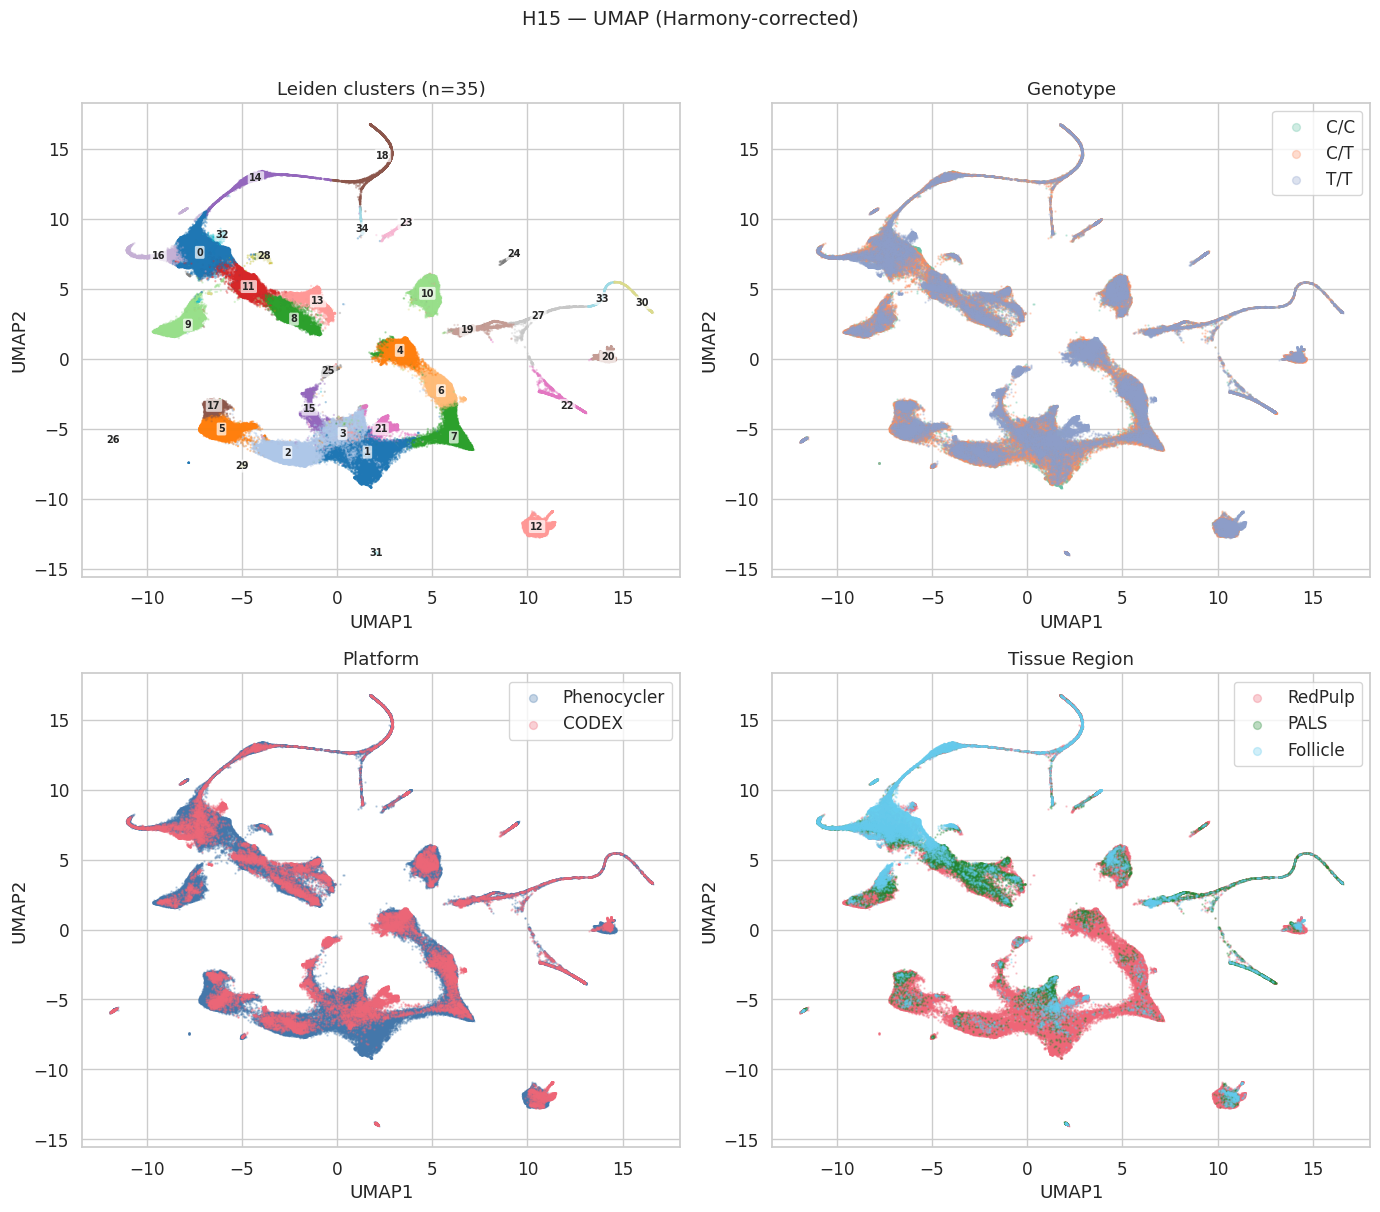

In [15]:
# ── UMAP visualization (2x2 grid) ──
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
umap_xy = adata_umap_sub.obsm["X_umap"]

# Panel 1: Leiden clusters with number labels
ax = axes[0, 0]
clusters = adata_umap_sub.obs["leiden"].astype(int).values
n_clust = clusters.max() + 1
cmap = plt.cm.get_cmap("tab20", n_clust)
sc_plot = ax.scatter(umap_xy[:, 0], umap_xy[:, 1], c=clusters, cmap=cmap,
                     s=0.5, alpha=0.3, rasterized=True)
# Add cluster number labels at centroids
for cl in range(n_clust):
    mask = clusters == cl
    if mask.any():
        cx = np.median(umap_xy[mask, 0])
        cy = np.median(umap_xy[mask, 1])
        ax.text(cx, cy, str(cl), fontsize=7, fontweight='bold',
                ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.15', facecolor='white',
                          edgecolor='none', alpha=0.7))
ax.set_title(f"Leiden clusters (n={n_clust})")
ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")

# Panel 2: Genotype
ax = axes[0, 1]
for geno in GENO_ORDER:
    mask = adata_umap_sub.obs["Genotype"].values == geno
    if mask.any():
        ax.scatter(umap_xy[mask, 0], umap_xy[mask, 1], c=[GENO_PALETTE[geno]],
                   s=0.5, alpha=0.3, label=geno, rasterized=True)
# Cells without genotype
no_geno = adata_umap_sub.obs["Genotype"].isna().values
if no_geno.any():
    ax.scatter(umap_xy[no_geno, 0], umap_xy[no_geno, 1], c="lightgrey",
               s=0.3, alpha=0.2, label="N/A", rasterized=True)
ax.legend(markerscale=8, frameon=True)
ax.set_title("Genotype")
ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")

# Panel 3: Platform
ax = axes[1, 0]
platform_colors = {"Phenocycler": "#4477AA", "CODEX": "#EE6677"}
for plat, color in platform_colors.items():
    mask = adata_umap_sub.obs["Platform"].values == plat
    if mask.any():
        ax.scatter(umap_xy[mask, 0], umap_xy[mask, 1], c=color,
                   s=0.5, alpha=0.3, label=plat, rasterized=True)
ax.legend(markerscale=8, frameon=True)
ax.set_title("Platform")
ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")

# Panel 4: Tissue region
ax = axes[1, 1]
region_colors = {"Follicle": "#66CCEE", "PALS": "#228833",
                 "RedPulp": "#EE6677", "Other": "#BBBBBB"}
for reg in ["Other", "RedPulp", "PALS", "Follicle"]:  # plot Other first
    mask = adata_umap_sub.obs["Region"].values == reg
    if mask.any():
        ax.scatter(umap_xy[mask, 0], umap_xy[mask, 1], c=region_colors.get(reg, "grey"),
                   s=0.5, alpha=0.3, label=reg, rasterized=True)
ax.legend(markerscale=8, frameon=True)
ax.set_title("Tissue Region")
ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")

plt.suptitle("H15 — UMAP (Harmony-corrected)", fontsize=14, y=1.01)
plt.tight_layout()
save_figure(fig, "H15_umap_overview")
plt.show()

Saved: analysis/figures/H15_cluster_marker_heatmap.png


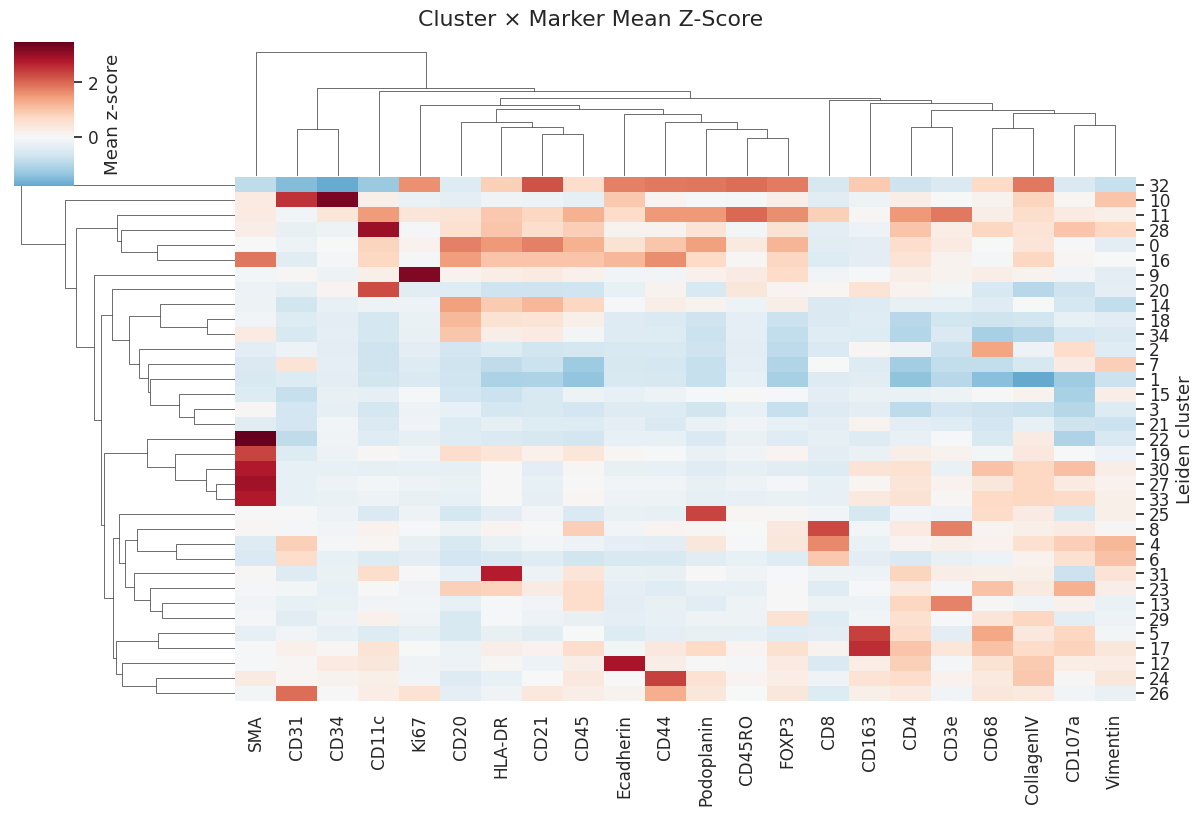

Saved: analysis/tables/H15_cluster_marker_means.csv


In [16]:
# ── Cluster-by-marker heatmap ──
cluster_ids = sorted(adata.obs["leiden"].unique(), key=int)
cluster_means = pd.DataFrame(index=cluster_ids, columns=CLUSTERING_MARKERS, dtype=float)

for cl in cluster_ids:
    mask = adata.obs["leiden"].values == cl
    cluster_means.loc[cl] = adata.X[mask].mean(axis=0)

# Hierarchical clustering of rows and columns
g = sns.clustermap(cluster_means.astype(float), cmap="RdBu_r", center=0,
                   figsize=(12, 8), row_cluster=True, col_cluster=True,
                   xticklabels=True, yticklabels=True,
                   cbar_kws={"label": "Mean z-score"})
g.ax_heatmap.set_ylabel("Leiden cluster")
g.ax_heatmap.set_xlabel("")
g.fig.suptitle("Cluster × Marker Mean Z-Score", y=1.02)
save_figure(g.fig, "H15_cluster_marker_heatmap")
plt.show()

save_table(cluster_means.reset_index().rename(columns={"index": "Cluster"}),
           "H15_cluster_marker_means")

In [17]:
# ── Cell type assignment (global Otsu + mutual exclusivity gates) ──
# Global Otsu thresholds: pool all z-scored values per marker across all images,
# compute one threshold per marker, apply uniformly. Since data is already
# z-scored per image (mean=0, std=1), scales are comparable across donors.
# Negative gates enforce known biological mutual exclusivity:
#   - CD20 (B) vs CD3e (T) — lymphoid lineage commitment
#   - CD4 vs CD8 — T cell co-receptor exclusivity
# Hierarchy: immune lineages first, structural markers last.

marker_idx = {m: i for i, m in enumerate(CLUSTERING_MARKERS)}
X = adata.X

def otsu_threshold(values, n_bins=256):
    """Otsu's method — threshold minimizing intra-class variance."""
    hist, bin_edges = np.histogram(values, bins=n_bins)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    total = hist.sum()
    if total == 0:
        return 0.0
    sum_total = (hist * bin_centers).sum()
    w0, sum0, max_var, best_t = 0, 0.0, -1, bin_centers[0]
    for i in range(len(hist)):
        w0 += hist[i]
        if w0 == 0:
            continue
        w1 = total - w0
        if w1 == 0:
            break
        sum0 += hist[i] * bin_centers[i]
        between_var = w0 * w1 * ((sum0 / w0) - ((sum_total - sum0) / w1)) ** 2
        if between_var > max_var:
            max_var = between_var
            best_t = bin_centers[i]
    return best_t

# ── Global Otsu — pool all z-scored values per marker ──
global_thresholds = {}
for mi, marker in enumerate(CLUSTERING_MARKERS):
    t = otsu_threshold(X[:, mi])
    global_thresholds[marker] = max(t, 0.0)

global_thresh_series = pd.Series(global_thresholds, name="Global_Otsu")
print("Global Otsu thresholds (z-score units):")
print(global_thresh_series.round(2).to_string())

# ── Per-image Otsu (diagnostic only — NOT used for gating) ──
images = adata.obs["Image"].values
unique_images = sorted(adata.obs["Image"].unique())

thresh_table = pd.DataFrame(index=unique_images, columns=CLUSTERING_MARKERS, dtype=float)
for image in unique_images:
    img_mask = images == image
    for mi, marker in enumerate(CLUSTERING_MARKERS):
        vals = X[img_mask, mi]
        t = otsu_threshold(vals)
        thresh_table.loc[image, marker] = max(t, 0.0)

# Combined table: GLOBAL row + per-image rows
global_row = global_thresh_series.to_frame().T
global_row.index = ["GLOBAL"]
combined_thresh = pd.concat([global_row, thresh_table])
print("\nPer-image Otsu thresholds (diagnostic only — not used for gating):")
print(thresh_table.round(2).to_string())
save_table(combined_thresh.reset_index().rename(columns={"index": "Image"}),
           "H15_otsu_thresholds")
print()

def is_high(marker):
    """Boolean mask: marker z-score exceeds global Otsu threshold."""
    mi = marker_idx[marker]
    return X[:, mi] > global_thresholds[marker]

# ── Pre-compute positive masks for mutual exclusivity ──
cd20_pos = is_high("CD20")
cd3e_pos = is_high("CD3e")
cd4_pos = is_high("CD4")
cd8_pos = is_high("CD8")

n = adata.shape[0]
cell_type = np.full(n, "Other", dtype=object)
assigned = np.zeros(n, dtype=bool)

# ── Immune lineages with negative gates ──

# B cell: CD20+ AND NOT CD3e+ (excludes doublets / spillover)
mask = cd20_pos & ~cd3e_pos & ~assigned
cell_type[mask] = "B cell"
assigned |= mask

# T cells: CD3e+ AND NOT CD20+ (excludes doublets / spillover)
t_mask = cd3e_pos & ~cd20_pos & ~assigned
cell_type[t_mask] = "T cell"
assigned |= t_mask

# CD4 subtype: CD4+ AND NOT CD8+ (mutual exclusivity)
th_mask = (cell_type == "T cell") & cd4_pos & ~cd8_pos
cell_type[th_mask] = "CD4 T cell"

# CD8 subtype: CD8+ AND NOT CD4+ (mutual exclusivity)
ct_mask = (cell_type == "T cell") & cd8_pos & ~cd4_pos
cell_type[ct_mask] = "CD8 T cell"

# T-reg: CD4 T cells that are FOXP3+
treg_mask = (cell_type == "CD4 T cell") & is_high("FOXP3")
cell_type[treg_mask] = "T-reg"

# Memory T cell: any remaining T cell (CD4, CD8, or generic) that is CD45RO+
# T-regs excluded — already reassigned above
mem_mask = np.isin(cell_type, ["T cell", "CD4 T cell", "CD8 T cell"]) & is_high("CD45RO")
cell_type[mem_mask] = "Memory T cell"

# FDC (CD21) — after B cells: captures CD21+/CD20− true FDCs
mask = is_high("CD21") & ~assigned
cell_type[mask] = "FDC"
assigned |= mask

# Macrophage (CD68) — exclude lymphocyte markers
mask = is_high("CD68") & ~cd20_pos & ~cd3e_pos & ~assigned
cell_type[mask] = "Macrophage"
assigned |= mask

# M2 macrophage (CD163) — exclude lymphocyte markers
mask = is_high("CD163") & ~cd20_pos & ~cd3e_pos & ~assigned
cell_type[mask] = "M2 Macrophage"
assigned |= mask

# DC (CD11c) — exclude lymphocyte markers
mask = is_high("CD11c") & ~cd20_pos & ~cd3e_pos & ~assigned
cell_type[mask] = "DC"
assigned |= mask

# ── Structural markers last (broadly expressed, spillover-prone) ──

# Endothelial (CD31)
mask = is_high("CD31") & ~assigned
cell_type[mask] = "Endothelial"
assigned |= mask

# Smooth Muscle Cell (SMA)
mask = is_high("SMA") & ~assigned
cell_type[mask] = "Smooth Muscle Cell"
assigned |= mask

# Stromal (Vimentin) — last, most ubiquitous
mask = is_high("Vimentin") & ~assigned
cell_type[mask] = "Stromal"
assigned |= mask

adata.obs["cell_type"] = cell_type

# Report
ct_counts = pd.Series(cell_type).value_counts()
ct_frac = ct_counts / n
print("Cell type distribution:")
for ct in ct_counts.index:
    print(f"  {ct:16s} {ct_counts[ct]:>8,}  ({ct_frac[ct]:5.1%})")

# Report doublet / ambiguous cells pushed to Other
n_cd20_cd3e = (cd20_pos & cd3e_pos).sum()
n_cd4_cd8 = (cd4_pos & cd8_pos & cd3e_pos).sum()
print(f"\nMutual exclusivity filtering:")
print(f"  CD20+/CD3e+ (B/T ambiguous): {n_cd20_cd3e:,} ({100*n_cd20_cd3e/n:.1f}%)")
print(f"  CD4+/CD8+ (T cell ambiguous): {n_cd4_cd8:,} ({100*n_cd4_cd8/n:.1f}%)")
print(f"  'Other' fraction: {ct_frac.get('Other', 0):.1%}")

Global Otsu thresholds (z-score units):
CD45RO        1.06
Ki67          1.30
CD20          0.39
CD4           0.00
CD44          0.69
CD31          0.43
CD11c         0.42
CD34          1.59
CD107a        0.00
CD163         0.92
HLA-DR        0.30
CD68          0.00
CD8           0.65
CD21          0.50
Vimentin      0.00
CD3e          0.51
CD45          0.00
Podoplanin    0.40
FOXP3         0.08
SMA           0.96
CollagenIV    0.00
Ecadherin     0.90



Per-image Otsu thresholds (diagnostic only — not used for gating):
                                                      CD45RO  Ki67  CD20   CD4  CD44  CD31  CD11c  CD34  CD107a  CD163  HLA-DR  CD68   CD8  CD21  Vimentin  CD3e  CD45  Podoplanin  FOXP3   SMA  CollagenIV  Ecadherin
1901HBMP004_PC29.ome.tiff                               2.30  2.38  0.54  2.17  0.39  0.06   0.11  0.00    0.58   0.00    0.00  0.52  0.93  1.19      0.00  1.43  0.81        0.00   2.30  0.88        0.01       1.58
HDL011_PC33.ome.tiff                                    0.71  1.10  0.66  0.00  0.38  0.34   0.28  1.61    0.06   0.70    0.66  0.55  0.26  0.32      0.00  0.51  0.00        0.01   0.00  0.74        0.00       0.68
HDL043_PC33.ome.tiff                                    1.47  1.43  0.23  0.00  0.98  0.46   0.54  1.96    0.03   1.41    0.45  0.00  0.56  0.71      0.00  0.39  0.00        0.49   0.16  0.98        0.00       1.54
HDL052SPLN_2025Aug6_Scan1.er.qptiff - resolution #1     1.52  1.94  0.91

Cell type distribution:
  Macrophage       5,466,876  (26.3%)
  B cell           4,349,868  (20.9%)
  Other            1,868,631  ( 9.0%)
  FDC              1,711,213  ( 8.2%)
  Stromal          1,658,962  ( 8.0%)
  Endothelial      1,538,502  ( 7.4%)
  T cell           1,280,946  ( 6.2%)
  T-reg             770,172  ( 3.7%)
  DC                485,231  ( 2.3%)
  Smooth Muscle Cell  485,027  ( 2.3%)
  CD8 T cell        448,561  ( 2.2%)
  CD4 T cell        346,009  ( 1.7%)
  Memory T cell     210,674  ( 1.0%)
  M2 Macrophage     161,435  ( 0.8%)

Mutual exclusivity filtering:
  CD20+/CD3e+ (B/T ambiguous): 1,825,866 (8.8%)
  CD4+/CD8+ (T cell ambiguous): 1,587,716 (7.6%)
  'Other' fraction: 9.0%


Saved: analysis/figures/H15_celltype_umap_validation.png


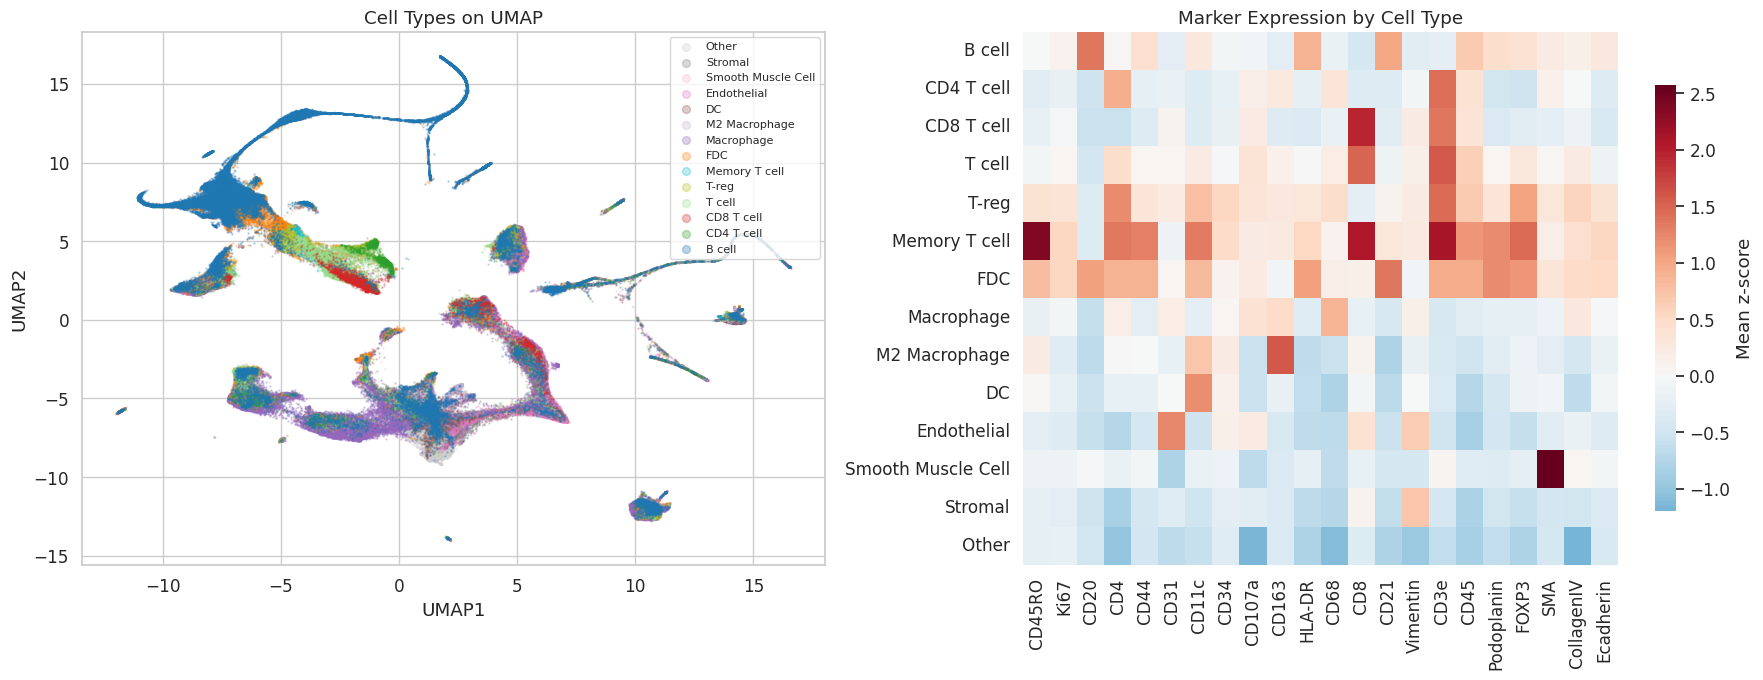

Saved: analysis/figures/H15_celltype_umap_by_genotype.png


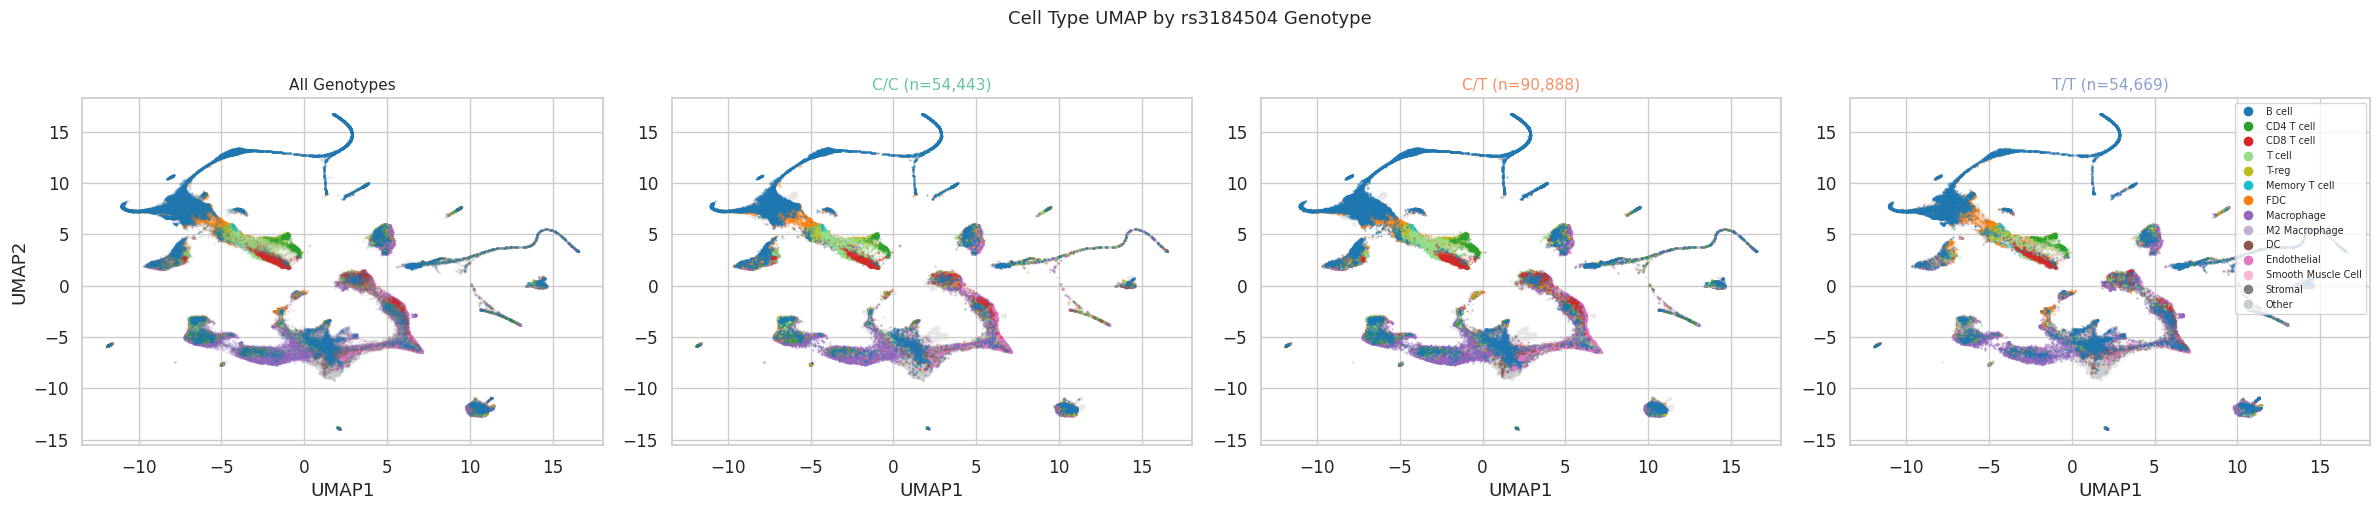

In [18]:
# ── Cell type UMAP + validation heatmap ──

# Propagate cell_type from full adata to UMAP subsample
adata_umap_sub.obs["cell_type"] = adata.obs.loc[adata_umap_sub.obs.index, "cell_type"].values

CELL_TYPE_ORDER = ["B cell", "CD4 T cell", "CD8 T cell", "T cell",
                   "T-reg", "Memory T cell",
                   "FDC", "Macrophage", "M2 Macrophage", "DC",
                   "Endothelial", "Smooth Muscle Cell", "Stromal", "Other"]
ct_palette = dict(zip(CELL_TYPE_ORDER,
    ["#1f77b4",   # B cell — blue
     "#2ca02c",   # CD4 T cell — green
     "#d62728",   # CD8 T cell — red
     "#98df8a",   # T cell — light green
     "#bcbd22",   # T-reg — olive
     "#17becf",   # Memory T cell — cyan
     "#ff7f0e",   # FDC — orange
     "#9467bd",   # Macrophage — purple
     "#c5b0d5",   # M2 Macrophage — light purple
     "#8c564b",   # DC — brown
     "#e377c2",   # Endothelial — pink
     "#f7b6d2",   # Smooth Muscle Cell — light pink
     "#7f7f7f",   # Stromal — grey
     "#cccccc",   # Other — light grey
    ]))

# ── Figure 1: Overview UMAP + validation heatmap ──
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

ax = axes[0]
umap_xy = adata_umap_sub.obsm["X_umap"]
for ct in reversed(CELL_TYPE_ORDER):
    mask = adata_umap_sub.obs["cell_type"].values == ct
    if mask.any():
        ax.scatter(umap_xy[mask, 0], umap_xy[mask, 1],
                   c=ct_palette.get(ct, "grey"), s=0.5, alpha=0.3,
                   label=ct, rasterized=True)
ax.legend(markerscale=8, frameon=True, fontsize=8, loc="upper right")
ax.set_title("Cell Types on UMAP")
ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")

ax = axes[1]
present_types = [ct for ct in CELL_TYPE_ORDER if ct in adata.obs["cell_type"].values]
ct_marker_means = pd.DataFrame(index=present_types, columns=CLUSTERING_MARKERS, dtype=float)
for ct in present_types:
    mask = adata.obs["cell_type"].values == ct
    ct_marker_means.loc[ct] = adata.X[mask].mean(axis=0)

sns.heatmap(ct_marker_means.astype(float), cmap="RdBu_r", center=0,
            ax=ax, xticklabels=True, yticklabels=True,
            cbar_kws={"label": "Mean z-score", "shrink": 0.8})
ax.set_title("Marker Expression by Cell Type")
ax.set_xlabel("")

plt.tight_layout()
save_figure(fig, "H15_celltype_umap_validation")
plt.show()

# ── Figure 2: Per-genotype UMAP ──
# Propagate genotype to UMAP subsample
adata_umap_sub.obs["Genotype"] = adata.obs.loc[adata_umap_sub.obs.index, "Genotype"].values

genotypes = [g for g in GENO_ORDER if g in adata_umap_sub.obs["Genotype"].values]
fig, axes = plt.subplots(1, len(genotypes) + 1, figsize=(6 * (len(genotypes) + 1), 5))

# First panel: all genotypes combined (reference)
ax = axes[0]
for ct in reversed(CELL_TYPE_ORDER):
    mask = adata_umap_sub.obs["cell_type"].values == ct
    if mask.any():
        ax.scatter(umap_xy[mask, 0], umap_xy[mask, 1],
                   c=ct_palette.get(ct, "grey"), s=0.3, alpha=0.2,
                   rasterized=True)
ax.set_title("All Genotypes", fontsize=11)
ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")

# Per-genotype panels
for i, geno in enumerate(genotypes):
    ax = axes[i + 1]
    geno_mask = adata_umap_sub.obs["Genotype"].values == geno
    n_geno = geno_mask.sum()

    # Grey background: all other cells
    ax.scatter(umap_xy[~geno_mask, 0], umap_xy[~geno_mask, 1],
               c="#e8e8e8", s=0.1, alpha=0.1, rasterized=True)

    # Foreground: this genotype colored by cell type
    for ct in reversed(CELL_TYPE_ORDER):
        ct_mask = geno_mask & (adata_umap_sub.obs["cell_type"].values == ct)
        if ct_mask.any():
            ax.scatter(umap_xy[ct_mask, 0], umap_xy[ct_mask, 1],
                       c=ct_palette.get(ct, "grey"), s=0.5, alpha=0.4,
                       label=ct, rasterized=True)

    ax.set_title(f"{geno} (n={n_geno:,})", fontsize=11,
                 color=GENO_PALETTE.get(geno, "black"))
    ax.set_xlabel("UMAP1"); ax.set_ylabel("")

# Shared legend on last panel
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=ct_palette[ct],
           markersize=8, label=ct) for ct in CELL_TYPE_ORDER if ct in adata_umap_sub.obs["cell_type"].values]
axes[-1].legend(handles=handles, fontsize=7, loc="upper right", frameon=True)

plt.suptitle("Cell Type UMAP by rs3184504 Genotype", fontsize=13, y=1.02)
plt.tight_layout()
save_figure(fig, "H15_celltype_umap_by_genotype")
plt.show()

---
## Genotype Analysis
Per-image cell-type proportions tested across rs3184504 genotype groups.

In [19]:
# ── Per-image cell type proportions ──
# Filter to cells with genotype
has_geno = adata.obs["Genotype"].notna()
obs_geno = adata.obs[has_geno].copy()
print(f"Cells with genotype: {has_geno.sum():,} / {adata.shape[0]:,}")
print(f"Samples: {sorted(obs_geno['Sample'].unique())}")

# Count cell types per sample
ct_counts = obs_geno.groupby(["Sample", "cell_type"], observed=True).size().reset_index(name="Count")
total_per_sample = obs_geno.groupby("Sample", observed=True).size().reset_index(name="Total")
ct_counts = ct_counts.merge(total_per_sample, on="Sample")
ct_counts["Proportion"] = ct_counts["Count"] / ct_counts["Total"]

# Pivot to wide format
prop_wide = ct_counts.pivot(index="Sample", columns="cell_type", values="Proportion").fillna(0)

# Add metadata
sample_meta = obs_geno.drop_duplicates("Sample").set_index("Sample")[["Genotype", "Platform"]]
prop_wide = prop_wide.join(sample_meta)

save_table(prop_wide.reset_index(), "H15_cell_type_proportions")
print(f"\nProportion table: {prop_wide.shape[0]} samples x {prop_wide.shape[1] - 2} cell types")
prop_wide.head()

Cells with genotype: 20,782,107 / 20,782,107
Samples: ['1901HBMP004', 'HDL011', 'HDL043', 'HDL052', 'HDL053', 'HDL055', 'HDL063', 'HDL070', 'HDL073', 'HDL079', 'HDL086']


Saved: analysis/tables/H15_cell_type_proportions.csv

Proportion table: 11 samples x 14 cell types


,B cell,CD4 T cell,CD8 T cell,DC,Endothelial,FDC,M2 Macrophage,Macrophage,Memory T cell,Other,Smooth Muscle Cell,Stromal,T cell,T-reg,Genotype,Platform
Sample,,,,,,,,,,,,,,,,
1901HBMP004,0.208851,0.002953,0.015299,0.077648,0.084621,0.026941,0.146391,0.245765,0.002430,0.084970,0.021966,0.045564,0.036397,0.000202,T/T,CODEX
HDL011,0.160392,0.014761,0.033227,0.040114,0.089304,0.113116,0.004586,0.198821,0.026403,0.082194,0.020500,0.126816,0.057432,0.032335,C/C,Phenocycler
HDL043,0.243389,0.016788,0.029658,0.004616,0.067671,0.061013,0.000800,0.247836,0.006580,0.108265,0.029701,0.066814,0.087281,0.029587,C/T,Phenocycler
HDL052,0.117703,0.013082,0.020263,0.017177,0.093943,0.115769,0.002569,0.273843,0.005784,0.135866,0.013758,0.089790,0.065196,0.035256,C/T,Phenocycler
HDL053,0.214910,0.017700,0.025276,0.008708,0.080964,0.081001,0.005039,0.284788,0.011223,0.065670,0.026756,0.072799,0.078165,0.027001,C/C,Phenocycler


Saved: analysis/figures/H15_celltype_stacked_bar.png


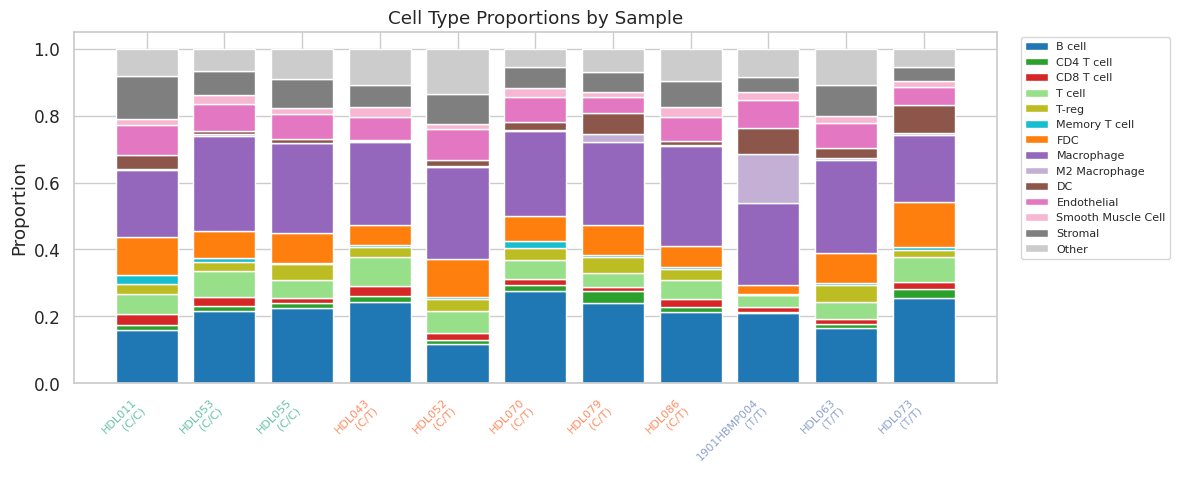

In [20]:
# ── Stacked bar chart of proportions by genotype ──
plot_types = [ct for ct in CELL_TYPE_ORDER if ct in prop_wide.columns and ct != "Other"]

# Sort samples by genotype
order = prop_wide.sort_values("Genotype").index

fig, ax = plt.subplots(figsize=(12, 5))
bottom = np.zeros(len(order))
for ct in plot_types:
    vals = prop_wide.loc[order, ct].values
    ax.bar(range(len(order)), vals, bottom=bottom, label=ct,
           color=ct_palette.get(ct, "grey"), width=0.8)
    bottom += vals

# "Other" last
if "Other" in prop_wide.columns:
    vals = prop_wide.loc[order, "Other"].values
    ax.bar(range(len(order)), vals, bottom=bottom, label="Other",
           color=ct_palette["Other"], width=0.8)

ax.set_xticks(range(len(order)))
# Color x-tick labels by genotype
labels = []
for s in order:
    g = str(prop_wide.loc[s, "Genotype"])
    labels.append(f"{s}\n({g})")
ax.set_xticklabels(labels, fontsize=8, rotation=45, ha="right")
for i, s in enumerate(order):
    g = str(prop_wide.loc[s, "Genotype"])
    ax.get_xticklabels()[i].set_color(GENO_PALETTE.get(g, "black"))

ax.set_ylabel("Proportion")
ax.set_title("Cell Type Proportions by Sample")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
save_figure(fig, "H15_celltype_stacked_bar")
plt.show()

Saved: analysis/figures/H15_celltype_genotype_boxplots.png


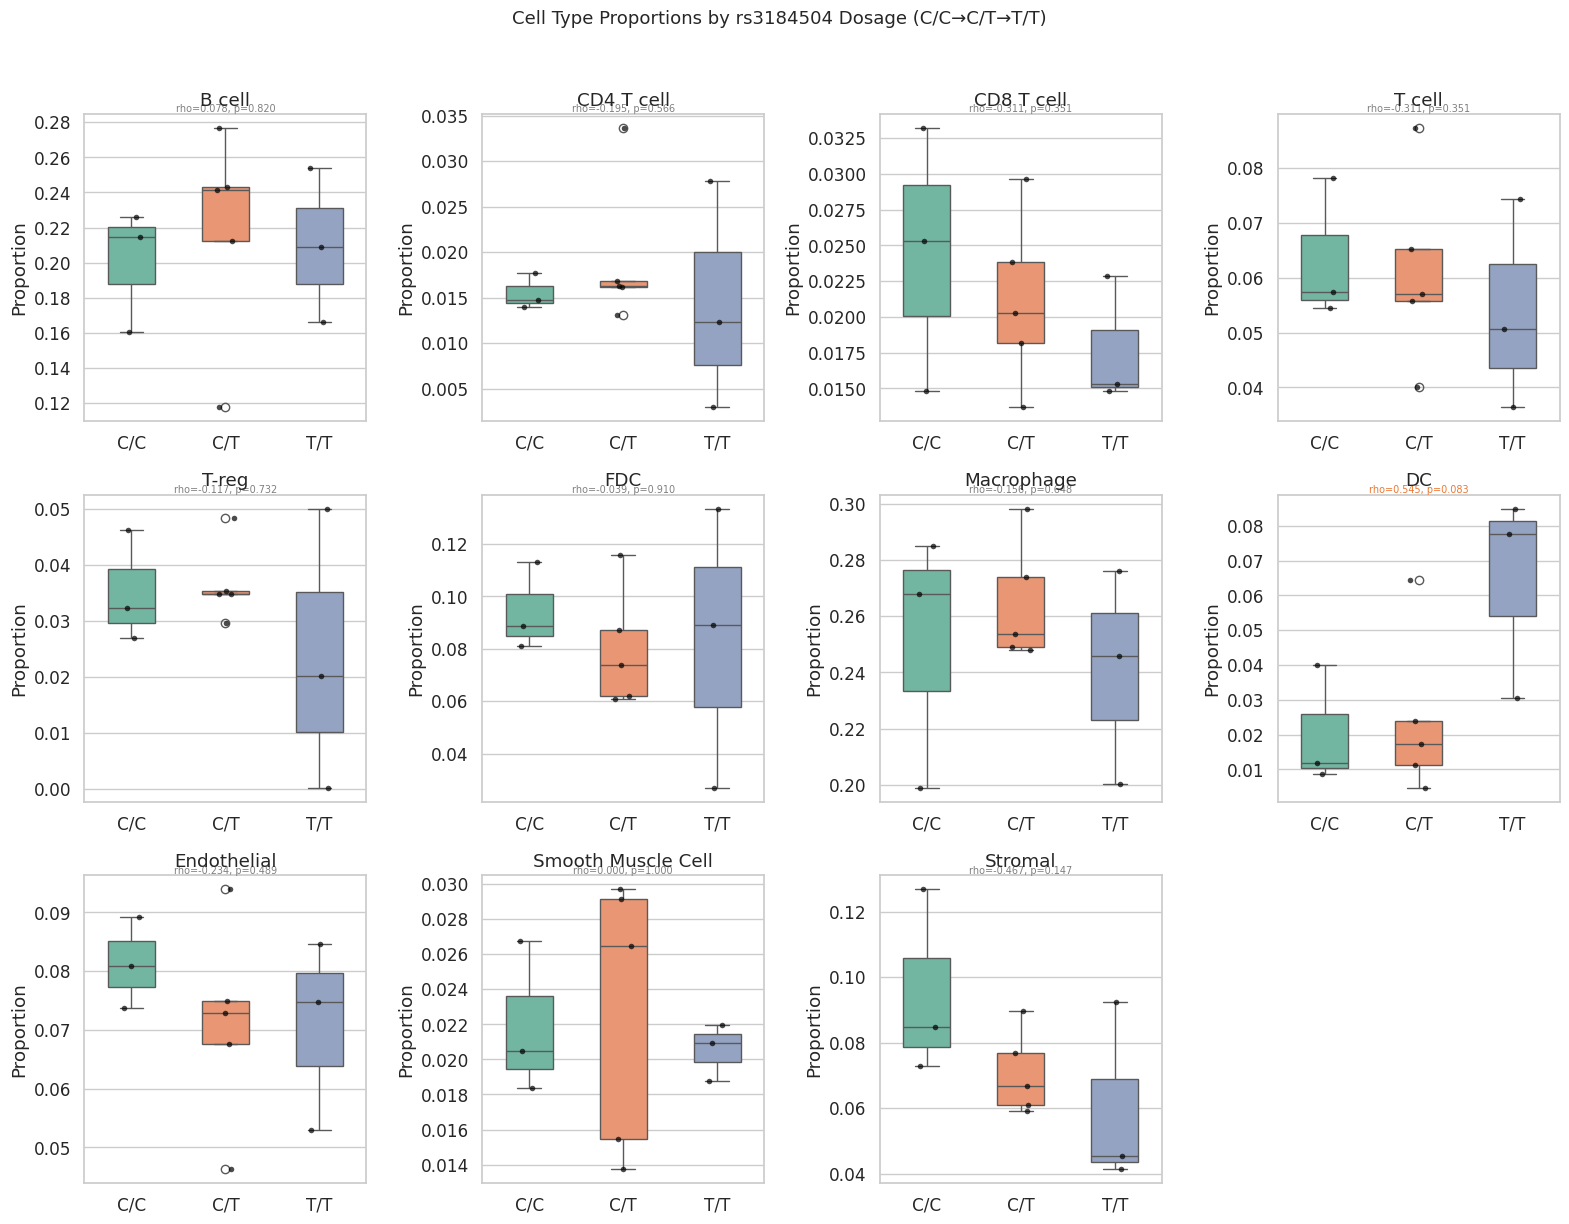

Saved: analysis/tables/H15_celltype_genotype_stats.csv

Significant results (p < 0.1):
                     Test Metric  Statistic        p Effect_Size
Mann-Whitney (C/T vs T/T)     DC   1.000000 0.071429     r=0.867
          Spearman dosage     DC   0.544949 0.082993   rho=0.545


In [21]:
# ── Cell type proportion boxplots by genotype + dosage trend ──
major_types = [ct for ct in CELL_TYPE_ORDER
               if ct in prop_wide.columns and ct != "Other"
               and prop_wide[ct].median() > 0.01]

n_types = len(major_types)
ncols = min(4, n_types)
nrows = (n_types + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)

all_stats = []
for i, ct in enumerate(major_types):
    ax = axes[i // ncols, i % ncols]
    plot_df = prop_wide[[ct, "Genotype"]].copy()
    plot_df["Genotype"] = plot_df["Genotype"].astype(str)

    sns.boxplot(data=plot_df, x="Genotype", y=ct, order=GENO_ORDER,
                palette=GENO_PALETTE, ax=ax, width=0.5)
    sns.stripplot(data=plot_df, x="Genotype", y=ct, order=GENO_ORDER,
                  color="black", size=4, alpha=0.7, ax=ax)
    ax.set_title(ct)
    ax.set_xlabel("")
    ax.set_ylabel("Proportion")

    stats = full_stats_table(prop_wide.assign(Genotype=prop_wide["Genotype"].astype(str)),
                             ct, label=ct)
    all_stats.append(stats)
    _annotate_dosage(ax, stats)

# Remove empty subplots
for j in range(n_types, nrows * ncols):
    axes[j // ncols, j % ncols].set_visible(False)

plt.suptitle("Cell Type Proportions by rs3184504 Dosage (C/C→C/T→T/T)",
             fontsize=13, y=1.02)
plt.tight_layout()
save_figure(fig, "H15_celltype_genotype_boxplots")
plt.show()

stats_df = pd.concat(all_stats, ignore_index=True)
save_table(stats_df, "H15_celltype_genotype_stats")
print("\nSignificant results (p < 0.1):")
sig = stats_df[stats_df["p"] < 0.1]
if len(sig):
    print(sig.to_string(index=False))
else:
    print("  None")

In [22]:
# ── Platform diagnostic ──
ct_cols = [ct for ct in CELL_TYPE_ORDER if ct in prop_wide.columns]
plat_df = prop_wide[ct_cols + ["Platform"]].copy()
plat_results = platform_diagnostic(plat_df, ct_cols)
save_table(plat_results, "H15_platform_diagnostic")

print("Platform diagnostic (CODEX vs Phenocycler):")
for _, row in plat_results.iterrows():
    flag = " ***" if row["p"] < 0.1 else ""
    print(f"  {row['Feature']:16s} p={row['p']:.4f}  r={row['rank_biserial']:.3f}{flag}")

confounded = plat_results[plat_results["p"] < 0.1]["Feature"].tolist()
if confounded:
    print(f"\nWARNING: Platform-confounded cell types: {confounded}")
else:
    print("\nNo significant platform effects detected.")

Saved: analysis/tables/H15_platform_diagnostic.csv
Platform diagnostic (CODEX vs Phenocycler):
  B cell           p=0.7273  r=-0.222
  CD4 T cell       p=0.9091  r=0.111
  CD8 T cell       p=0.9091  r=0.111
  T cell           p=0.7273  r=0.222
  T-reg            p=0.0364  r=1.000 ***
  Memory T cell    p=0.5818  r=0.333
  FDC              p=1.0000  r=0.000
  Macrophage       p=0.1455  r=0.778
  M2 Macrophage    p=0.2182  r=-0.667
  DC               p=0.0364  r=-1.000 ***
  Endothelial      p=0.9091  r=0.111
  Smooth Muscle Cell p=0.9091  r=0.111
  Stromal          p=0.0364  r=1.000 ***
  Other            p=0.3273  r=0.556



---
## Regional Cell Type Analysis
Cell type composition varies by tissue region. Test genotype effects within each region.

Saved: analysis/figures/H15_region_celltype_heatmap.png


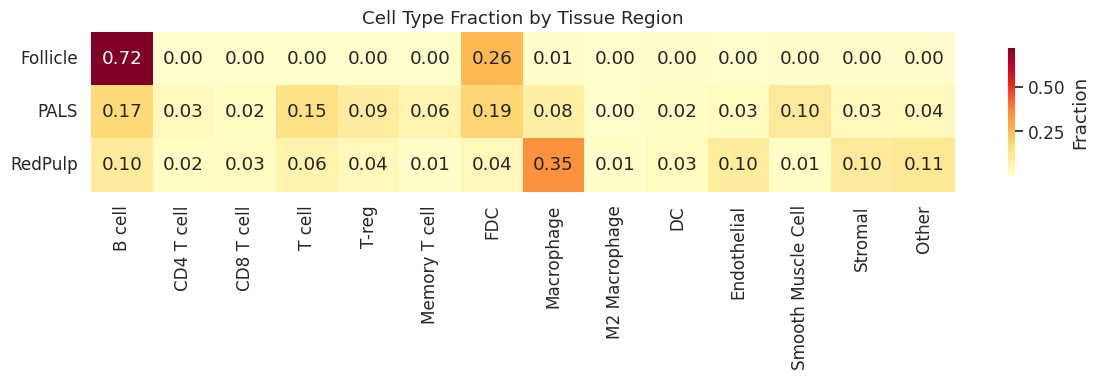


Region-specific genotype tests:


Saved: analysis/tables/H15_region_celltype_genotype_stats.csv
                     Test                  Metric        p Effect_Size
           Kruskal-Wallis         Follicle:B cell 0.072057            
Mann-Whitney (C/T vs T/T)         Follicle:B cell 0.035714    r=-1.000
          Spearman dosage     Follicle:CD4 T cell 0.051264   rho=0.629
          Spearman dosage             PALS:B cell 0.082993  rho=-0.545
          Spearman dosage         PALS:CD4 T cell 0.082993   rho=0.545
          Spearman dosage         PALS:Macrophage 0.059300  rho=-0.584
          Spearman dosage PALS:Smooth Muscle Cell 0.059300   rho=0.584
Mann-Whitney (C/T vs T/T)              RedPulp:DC 0.071429     r=0.867
          Spearman dosage              RedPulp:DC 0.082993   rho=0.545
Mann-Whitney (C/C vs C/T)         RedPulp:Stromal 0.035714    r=-1.000
          Spearman dosage         RedPulp:Stromal 0.059300  rho=-0.584


In [23]:
# ── Cell type by region heatmap + region-specific genotype tests ──
obs_geno = adata.obs[adata.obs["Genotype"].notna()].copy()
region_ct = obs_geno.groupby(["Region", "cell_type"], observed=True).size().reset_index(name="n")
region_total = obs_geno.groupby("Region", observed=True).size().reset_index(name="total")
region_ct = region_ct.merge(region_total, on="Region")
region_ct["frac"] = region_ct["n"] / region_ct["total"]

# Heatmap: fraction of each cell type in each region
hm_data = region_ct.pivot(index="Region", columns="cell_type", values="frac").fillna(0)
# Order regions and cell types
region_order = [r for r in ["Follicle", "PALS", "RedPulp", "Other"] if r in hm_data.index]
ct_order = [ct for ct in CELL_TYPE_ORDER if ct in hm_data.columns]
hm_data = hm_data.loc[region_order, ct_order]

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(hm_data, cmap="YlOrRd", annot=True, fmt=".2f", ax=ax,
            cbar_kws={"label": "Fraction", "shrink": 0.8})
ax.set_title("Cell Type Fraction by Tissue Region")
ax.set_ylabel(""); ax.set_xlabel("")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, va="center")
plt.tight_layout()
save_figure(fig, "H15_region_celltype_heatmap")
plt.show()

# Region-specific genotype tests
print("\nRegion-specific genotype tests:")
region_stats = []
for region in ["Follicle", "PALS", "RedPulp"]:
    reg_cells = obs_geno[obs_geno["Region"] == region]
    # Per-sample cell type proportions within this region
    reg_ct = reg_cells.groupby(["Sample", "cell_type"], observed=True).size().reset_index(name="n")
    reg_total = reg_cells.groupby("Sample", observed=True).size().reset_index(name="total")
    reg_ct = reg_ct.merge(reg_total, on="Sample")
    reg_ct["Proportion"] = reg_ct["n"] / reg_ct["total"]
    reg_ct["Genotype"] = reg_ct["Sample"].map(GENOTYPE_MAP)

    for ct in major_types:
        ct_data = reg_ct[reg_ct["cell_type"] == ct]
        if len(ct_data) < 3:
            continue
        stats = full_stats_table(ct_data, "Proportion", label=f"{region}:{ct}")
        region_stats.append(stats)

if region_stats:
    region_stats_df = pd.concat(region_stats, ignore_index=True)
    save_table(region_stats_df, "H15_region_celltype_genotype_stats")
    sig = region_stats_df[region_stats_df["p"] < 0.1]
    if len(sig):
        print(sig[["Test", "Metric", "p", "Effect_Size"]].to_string(index=False))
    else:
        print("  No significant results at p < 0.1")
else:
    print("  Insufficient data for region-specific tests")

---
## Distance Analysis
Mean signed distance from each cell type to tissue structures, by genotype.

Saved: analysis/tables/H15_celltype_distances.csv
Distance records: 462


Saved: analysis/figures/H15_distance_heatmap.png


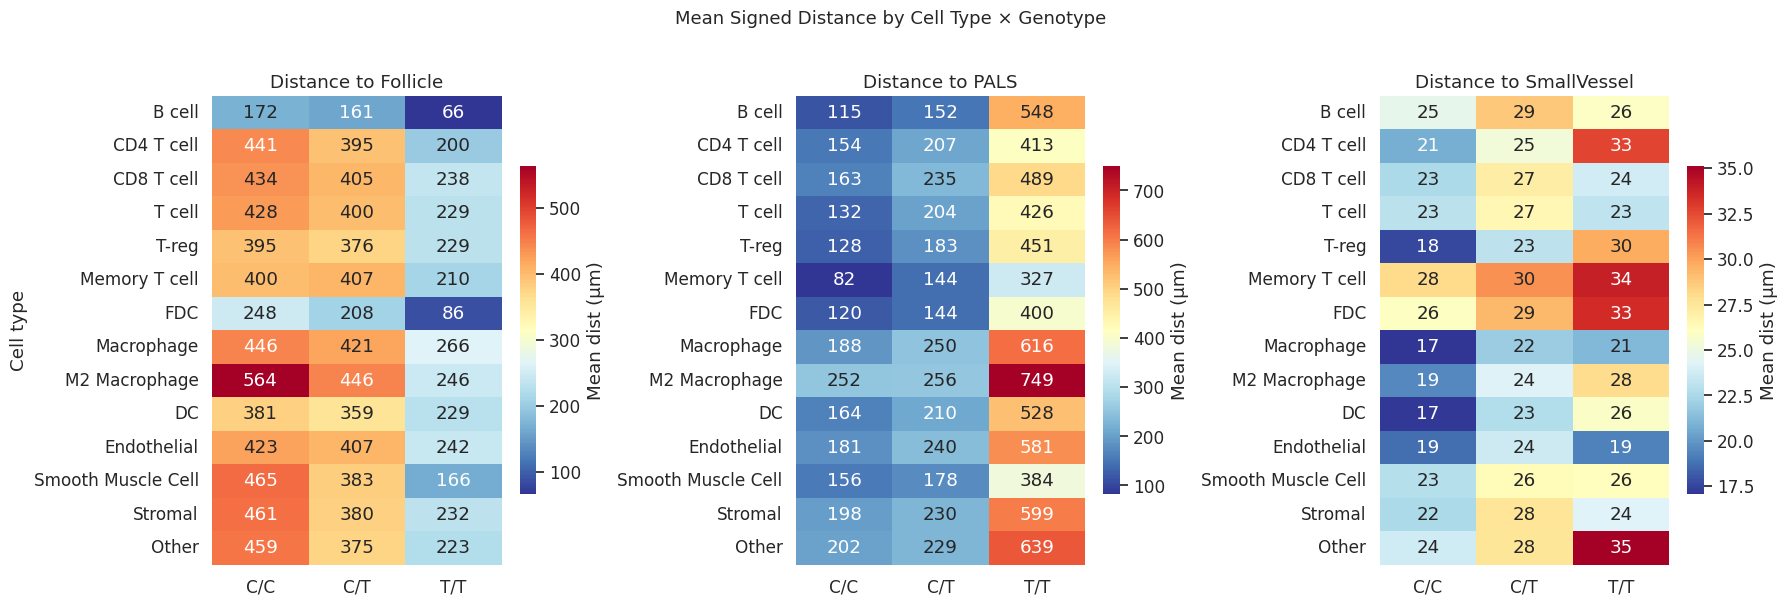

In [24]:
# ── Mean signed distance by cell type and genotype ──
obs_geno = adata.obs[adata.obs["Genotype"].notna()].copy()

# Structures of interest for distance analysis
structures = ["Follicle", "PALS", "SmallVessel"]
# Follicle and PALS are measured against the region layer, so they agree with
# the Region labels. SmallVessel keeps QuPath's column: the region layer holds
# no vessel polygons, by design — vessels come from the annotation CSV instead.
dist_col_map = {"Follicle": "dist_Follicle_um",
                "PALS": "dist_PALS_um",
                "SmallVessel": "Signed distance to annotation SmallVessel \u00b5m"}

# Per-sample: mean distance and fraction inside for each cell type x structure
dist_records = []
for sample in obs_geno["Sample"].unique():
    s_data = obs_geno[obs_geno["Sample"] == sample]
    geno = s_data["Genotype"].iloc[0]
    for ct in CELL_TYPE_ORDER:
        ct_data = s_data[s_data["cell_type"] == ct]
        if len(ct_data) < 10:
            continue
        for struct, dcol in dist_col_map.items():
            vals = ct_data[dcol].values
            dist_records.append({
                "Sample": sample, "Genotype": geno,
                "cell_type": ct, "Structure": struct,
                "mean_dist": np.mean(vals),
                "median_dist": np.median(vals),
                "frac_inside": np.mean(vals < 0),
                "n_cells": len(vals),
            })

dist_df = pd.DataFrame(dist_records)
save_table(dist_df, "H15_celltype_distances")
print(f"Distance records: {len(dist_df):,}")

# Heatmap: mean distance to each structure by cell type x genotype (3 panels)
fig, axes = plt.subplots(1, len(structures), figsize=(6 * len(structures), 6))
for j, struct in enumerate(structures):
    ax = axes[j]
    sub = dist_df[dist_df["Structure"] == struct]
    pivot = sub.pivot_table(index="cell_type", columns="Genotype",
                            values="mean_dist", aggfunc="mean")
    pivot = pivot.reindex(index=[ct for ct in CELL_TYPE_ORDER if ct in pivot.index],
                          columns=GENO_ORDER)
    sns.heatmap(pivot, cmap="RdYlBu_r", annot=True, fmt=".0f", ax=ax,
                cbar_kws={"label": "Mean dist (\u00b5m)", "shrink": 0.7})
    ax.set_title(f"Distance to {struct}")
    ax.set_ylabel("" if j > 0 else "Cell type")
    ax.set_xlabel("")

plt.suptitle("Mean Signed Distance by Cell Type \u00d7 Genotype", fontsize=13, y=1.01)
plt.tight_layout()
save_figure(fig, "H15_distance_heatmap")
plt.show()

In [25]:
# ── Distance stats — genotype tests on key cell type × structure pairs ──
KEY_PAIRS = [
    ("B cell",      "Follicle"),
    ("CD4 T cell",  "PALS"),
    ("CD8 T cell",  "PALS"),
    ("Macrophage",  "SmallVessel"),
    ("Endothelial", "SmallVessel"),
    ("FDC",         "Follicle"),
]

all_dist_stats = []
for ct, struct in KEY_PAIRS:
    sub = dist_df[(dist_df["cell_type"] == ct) & (dist_df["Structure"] == struct)]
    if len(sub) < 3:
        print(f"  {ct} × {struct}: insufficient data")
        continue

    # Test mean distance
    stats_mean = full_stats_table(sub, "mean_dist", label=f"{ct}-{struct} mean_dist")
    all_dist_stats.append(stats_mean)

    # Test fraction inside
    stats_frac = full_stats_table(sub, "frac_inside", label=f"{ct}-{struct} frac_inside")
    all_dist_stats.append(stats_frac)

if all_dist_stats:
    dist_stats_df = pd.concat(all_dist_stats, ignore_index=True)
    save_table(dist_stats_df, "H15_distance_genotype_stats")
    print("\nSignificant results (p < 0.1):")
    sig = dist_stats_df[dist_stats_df["p"] < 0.1]
    if len(sig):
        print(sig[["Test", "Metric", "p", "Effect_Size"]].to_string(index=False))
    else:
        print("  None")
else:
    print("  No distance tests computed")

Saved: analysis/tables/H15_distance_genotype_stats.csv

Significant results (p < 0.1):
           Test                      Metric        p Effect_Size
Spearman dosage   CD8 T cell-PALS mean_dist 0.082993   rho=0.545
Spearman dosage CD8 T cell-PALS frac_inside 0.026572  rho=-0.662


---
## Spatial Neighborhood Analysis
k-NN neighborhoods (k=20) characterize local cell-type composition around each cell.

In [26]:
# ── Compute spatial k-NN neighborhoods per image (parallelized) ──
from joblib import Parallel, delayed

obs_geno = adata.obs[adata.obs["Genotype"].notna()].copy()
obs_geno["_idx"] = np.arange(len(obs_geno))

present_types = sorted(obs_geno["cell_type"].unique())
type_to_int = {ct: i for i, ct in enumerate(present_types)}
n_types = len(present_types)

def process_image_neighbors(image, obs_geno, type_to_int, k):
    """Compute neighborhood composition for one image."""
    img_data = obs_geno[obs_geno["Image"] == image]
    if len(img_data) < k + 1:
        return []

    sample = img_data["Sample"].iloc[0]
    geno = img_data["Genotype"].iloc[0]
    coords = img_data[[X_COL, Y_COL]].values
    types_int = img_data["cell_type"].map(type_to_int).values

    tree = cKDTree(coords)
    _, indices = tree.query(coords, k=k + 1)  # +1 for self
    neighbor_idx = indices[:, 1:]  # exclude self

    neighbor_types = types_int[neighbor_idx]  # (n_cells, k)
    records = []
    for ct_name, ct_int in type_to_int.items():
        ct_mask = types_int == ct_int
        if ct_mask.sum() < 10:
            continue
        ct_neighbors = neighbor_types[ct_mask]
        for nb_name, nb_int in type_to_int.items():
            frac = (ct_neighbors == nb_int).mean()
            records.append({
                "Image": image, "Sample": sample, "Genotype": geno,
                "cell_type": ct_name, "neighbor_type": nb_name,
                "frac": frac,
            })
    return records

results = Parallel(n_jobs=-1, verbose=1)(
    delayed(process_image_neighbors)(img, obs_geno, type_to_int, SPATIAL_K)
    for img in obs_geno["Image"].unique()
)
neigh_records = [r for batch in results for r in batch]

neigh_df = pd.DataFrame(neigh_records)
save_table(neigh_df, "H15_neighborhood_composition")
print(f"Neighborhood records: {len(neigh_df):,}")
print(f"Images: {neigh_df['Image'].nunique()}, cell types: {neigh_df['cell_type'].nunique()}")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 32 concurrent workers.


[Parallel(n_jobs=-1)]: Done   8 out of  11 | elapsed:  3.4min remaining:  1.3min


[Parallel(n_jobs=-1)]: Done  11 out of  11 | elapsed:  4.7min finished


Saved: analysis/tables/H15_neighborhood_composition.csv
Neighborhood records: 2,156
Images: 11, cell types: 14


Saved: analysis/figures/H15_neighborhood_enrichment.png


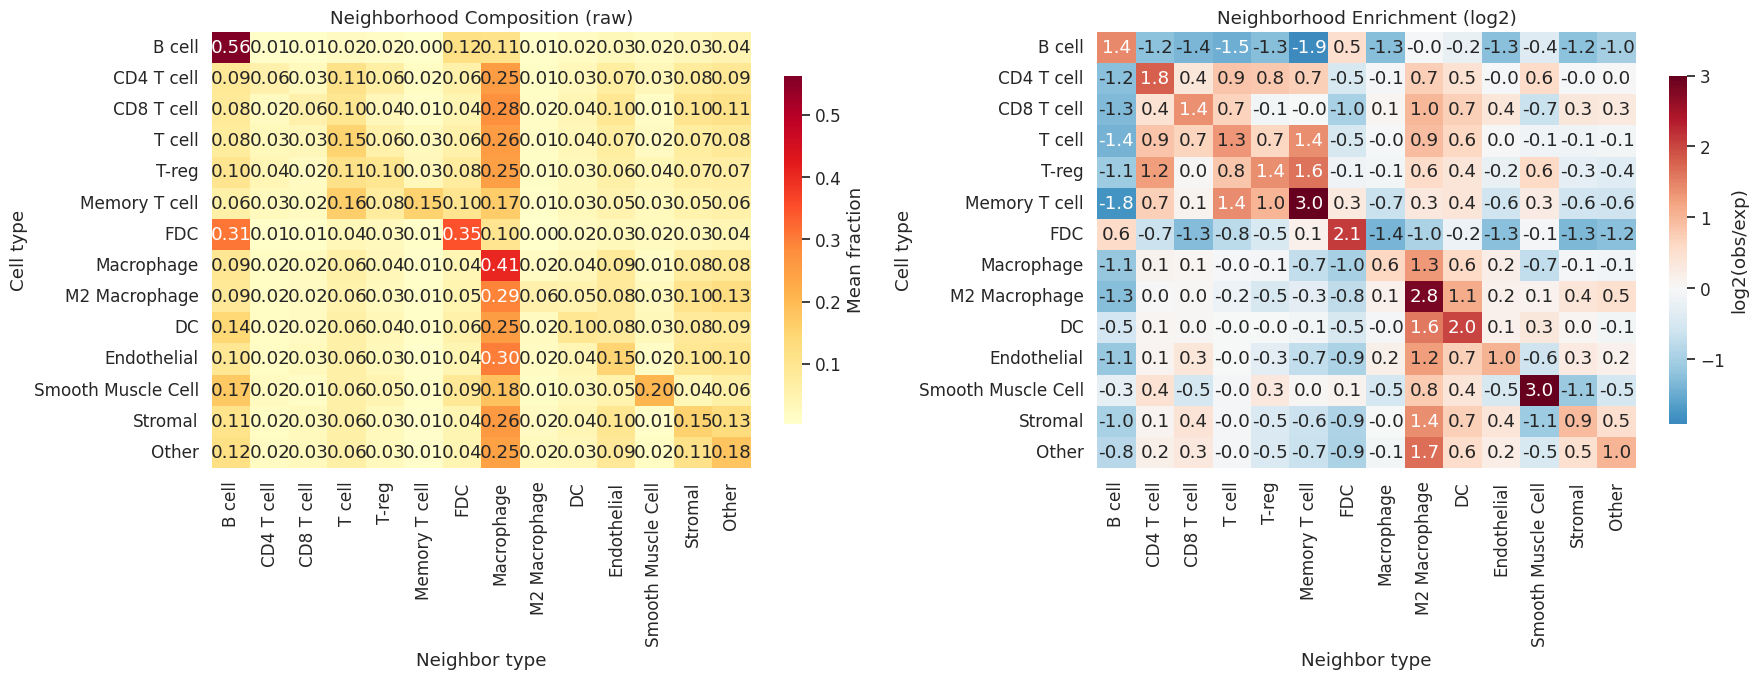

In [27]:
# ── Neighborhood enrichment heatmap ──
# Average across images
mean_comp = neigh_df.groupby(["cell_type", "neighbor_type"], observed=True)["frac"].mean()
mean_comp = mean_comp.unstack(fill_value=0)

# Overall cell type proportions (expected by chance)
all_types = obs_geno["cell_type"].value_counts(normalize=True)

# Log2 enrichment
expected = all_types.reindex(mean_comp.columns, fill_value=1e-6)
enrichment = np.log2(mean_comp / expected)
enrichment = enrichment.clip(-3, 3)  # clip extremes

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Order by CELL_TYPE_ORDER
ct_order = [ct for ct in CELL_TYPE_ORDER if ct in mean_comp.index]
nb_order = [ct for ct in CELL_TYPE_ORDER if ct in mean_comp.columns]

# Raw composition
sns.heatmap(mean_comp.loc[ct_order, nb_order], cmap="YlOrRd", annot=True, fmt=".2f",
            ax=axes[0], cbar_kws={"label": "Mean fraction", "shrink": 0.8})
axes[0].set_title("Neighborhood Composition (raw)")
axes[0].set_xlabel("Neighbor type"); axes[0].set_ylabel("Cell type")

# Log2 enrichment
sns.heatmap(enrichment.loc[ct_order, nb_order], cmap="RdBu_r", center=0,
            annot=True, fmt=".1f", ax=axes[1],
            cbar_kws={"label": "log2(obs/exp)", "shrink": 0.8})
axes[1].set_title("Neighborhood Enrichment (log2)")
axes[1].set_xlabel("Neighbor type"); axes[1].set_ylabel("Cell type")

plt.tight_layout()
save_figure(fig, "H15_neighborhood_enrichment")
plt.show()

Saved: analysis/figures/H15_neighborhood_genotype_boxplots.png


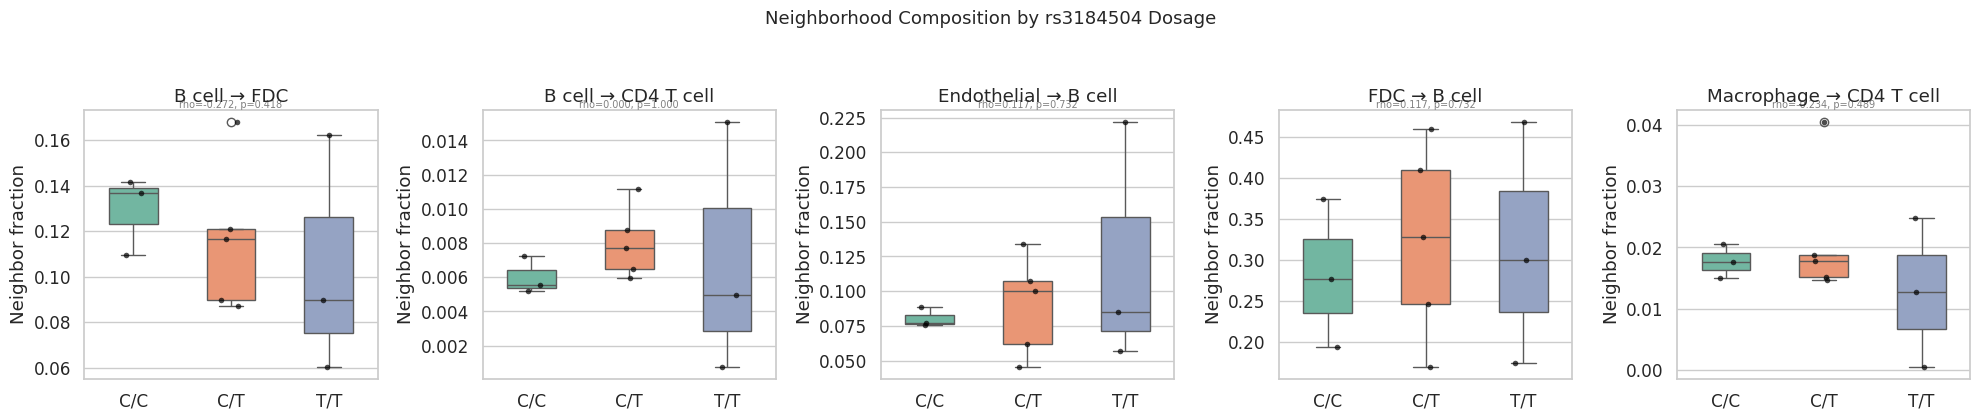

Saved: analysis/tables/H15_neighborhood_genotype_stats.csv

Significant results (p < 0.1):
  None


In [28]:
# ── Neighborhood composition by genotype — key pairs ──
NEIGH_KEY_PAIRS = [
    ("B cell",      "FDC"),
    ("B cell",      "CD4 T cell"),
    ("Endothelial", "B cell"),
    ("FDC",         "B cell"),
    ("Macrophage",  "CD4 T cell"),
]

n_pairs = len(NEIGH_KEY_PAIRS)
fig, axes = plt.subplots(1, n_pairs, figsize=(4 * n_pairs, 4), squeeze=False)

neigh_stats = []
for i, (ct, nb) in enumerate(NEIGH_KEY_PAIRS):
    ax = axes[0, i]
    sub = neigh_df[(neigh_df["cell_type"] == ct) & (neigh_df["neighbor_type"] == nb)].copy()
    if len(sub) < 3:
        ax.set_title(f"{ct}\u2192{nb}\n(no data)")
        continue

    sub["Genotype"] = sub["Genotype"].astype(str)
    sns.boxplot(data=sub, x="Genotype", y="frac", order=GENO_ORDER,
                palette=GENO_PALETTE, ax=ax, width=0.5)
    sns.stripplot(data=sub, x="Genotype", y="frac", order=GENO_ORDER,
                  color="black", size=4, alpha=0.7, ax=ax)
    ax.set_title(f"{ct} \u2192 {nb}")
    ax.set_xlabel(""); ax.set_ylabel("Neighbor fraction")

    stats = full_stats_table(sub, "frac", label=f"{ct}\u2192{nb}")
    neigh_stats.append(stats)
    _annotate_dosage(ax, stats)

plt.suptitle("Neighborhood Composition by rs3184504 Dosage", fontsize=13, y=1.05)
plt.tight_layout()
save_figure(fig, "H15_neighborhood_genotype_boxplots")
plt.show()

if neigh_stats:
    neigh_stats_df = pd.concat(neigh_stats, ignore_index=True)
    save_table(neigh_stats_df, "H15_neighborhood_genotype_stats")
    sig = neigh_stats_df[neigh_stats_df["p"] < 0.1]
    print("\nSignificant results (p < 0.1):")
    if len(sig):
        print(sig[["Test", "Metric", "p", "Effect_Size"]].to_string(index=False))
    else:
        print("  None")

Saved: analysis/figures/H15_neighborhood_diversity.png


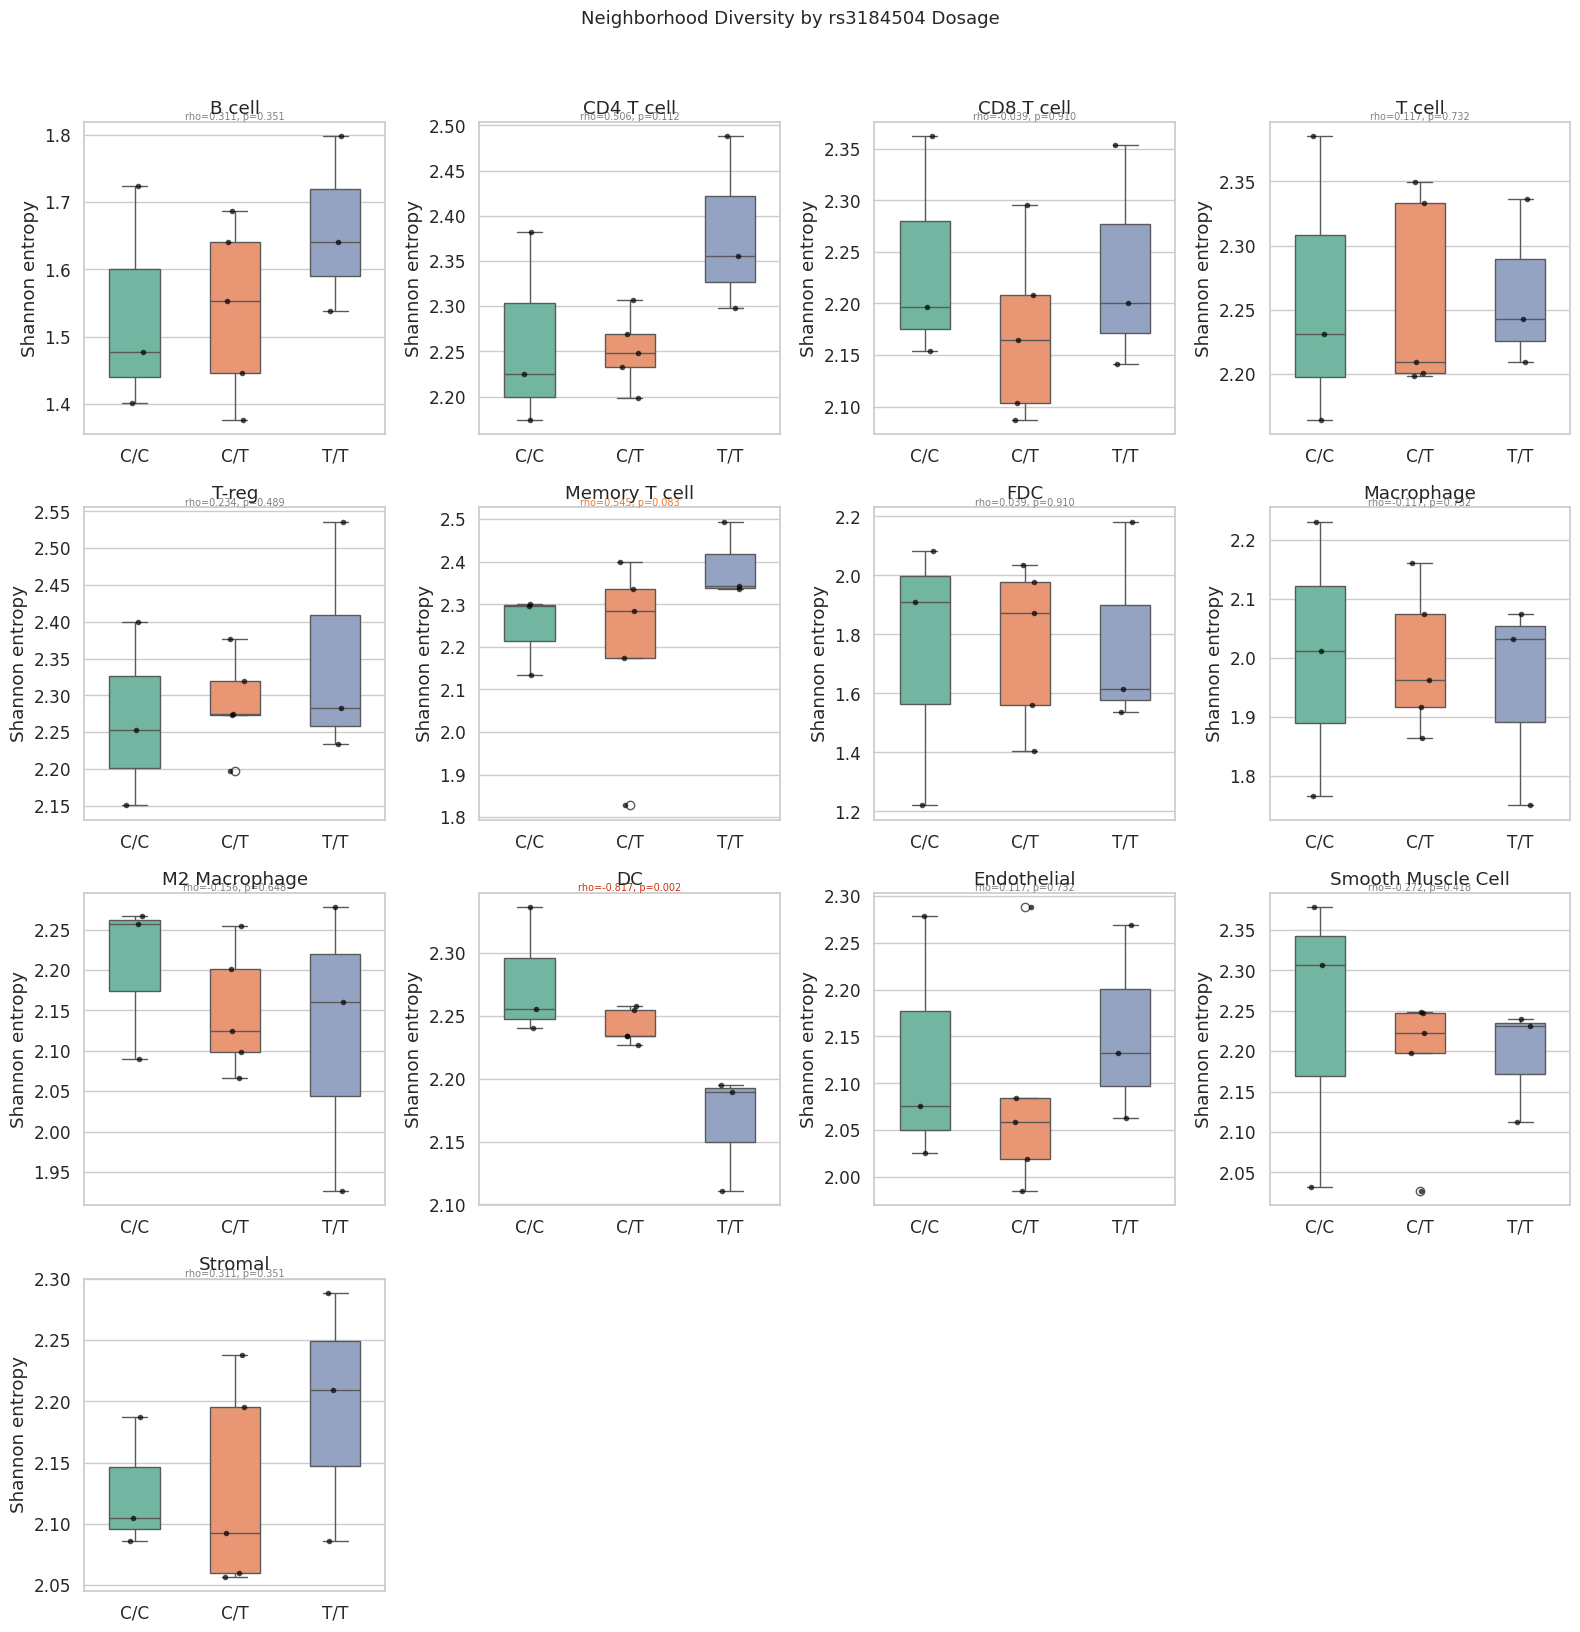

Saved: analysis/tables/H15_diversity_stats.csv
Significant (p < 0.1):
                     Test                  Metric        p Effect_Size
Mann-Whitney (C/T vs T/T)    CD4 T cell diversity 0.071429     r=0.867
          Spearman dosage Memory T cell diversity 0.082993   rho=0.545
           Kruskal-Wallis            DC diversity 0.030473            
Mann-Whitney (C/T vs T/T)            DC diversity 0.035714    r=-1.000
          Spearman dosage            DC diversity 0.002120  rho=-0.817


In [29]:
# ── Neighborhood diversity by genotype ──
from scipy.stats import entropy

# Shannon entropy of neighborhood composition per cell type per sample
div_records = []
for (sample, ct), grp in neigh_df.groupby(["Sample", "cell_type"], observed=True):
    fracs = grp.set_index("neighbor_type")["frac"].values
    fracs = fracs[fracs > 0]
    if len(fracs) < 2:
        continue
    h = entropy(fracs)
    div_records.append({
        "Sample": sample,
        "Genotype": grp["Genotype"].iloc[0],
        "cell_type": ct,
        "Shannon_H": h,
    })

div_df = pd.DataFrame(div_records)

# Boxplots for major cell types
div_types = [ct for ct in CELL_TYPE_ORDER
             if ct in div_df["cell_type"].values and ct != "Other"]
n_dt = len(div_types)
ncols = min(4, n_dt)
nrows = (n_dt + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)

div_stats = []
for i, ct in enumerate(div_types):
    ax = axes[i // ncols, i % ncols]
    sub = div_df[div_df["cell_type"] == ct].copy()
    sub["Genotype"] = sub["Genotype"].astype(str)
    sns.boxplot(data=sub, x="Genotype", y="Shannon_H", order=GENO_ORDER,
                palette=GENO_PALETTE, ax=ax, width=0.5)
    sns.stripplot(data=sub, x="Genotype", y="Shannon_H", order=GENO_ORDER,
                  color="black", size=4, alpha=0.7, ax=ax)
    ax.set_title(ct); ax.set_xlabel(""); ax.set_ylabel("Shannon entropy")

    if len(sub) >= 3:
        stats = full_stats_table(sub, "Shannon_H", label=f"{ct} diversity")
        div_stats.append(stats)
        _annotate_dosage(ax, stats)

for j in range(n_dt, nrows * ncols):
    axes[j // ncols, j % ncols].set_visible(False)

plt.suptitle("Neighborhood Diversity by rs3184504 Dosage", fontsize=13, y=1.02)
plt.tight_layout()
save_figure(fig, "H15_neighborhood_diversity")
plt.show()

if div_stats:
    div_stats_df = pd.concat(div_stats, ignore_index=True)
    save_table(div_stats_df, "H15_diversity_stats")
    sig = div_stats_df[div_stats_df["p"] < 0.1]
    print("Significant (p < 0.1):")
    if len(sig):
        print(sig[["Test", "Metric", "p", "Effect_Size"]].to_string(index=False))
    else:
        print("  None")

---
## Spatial Cell Type Maps
Scatter plots of cells colored by assigned cell type within crop windows.

Saved: analysis/figures/H15_spatial_celltype_maps.png


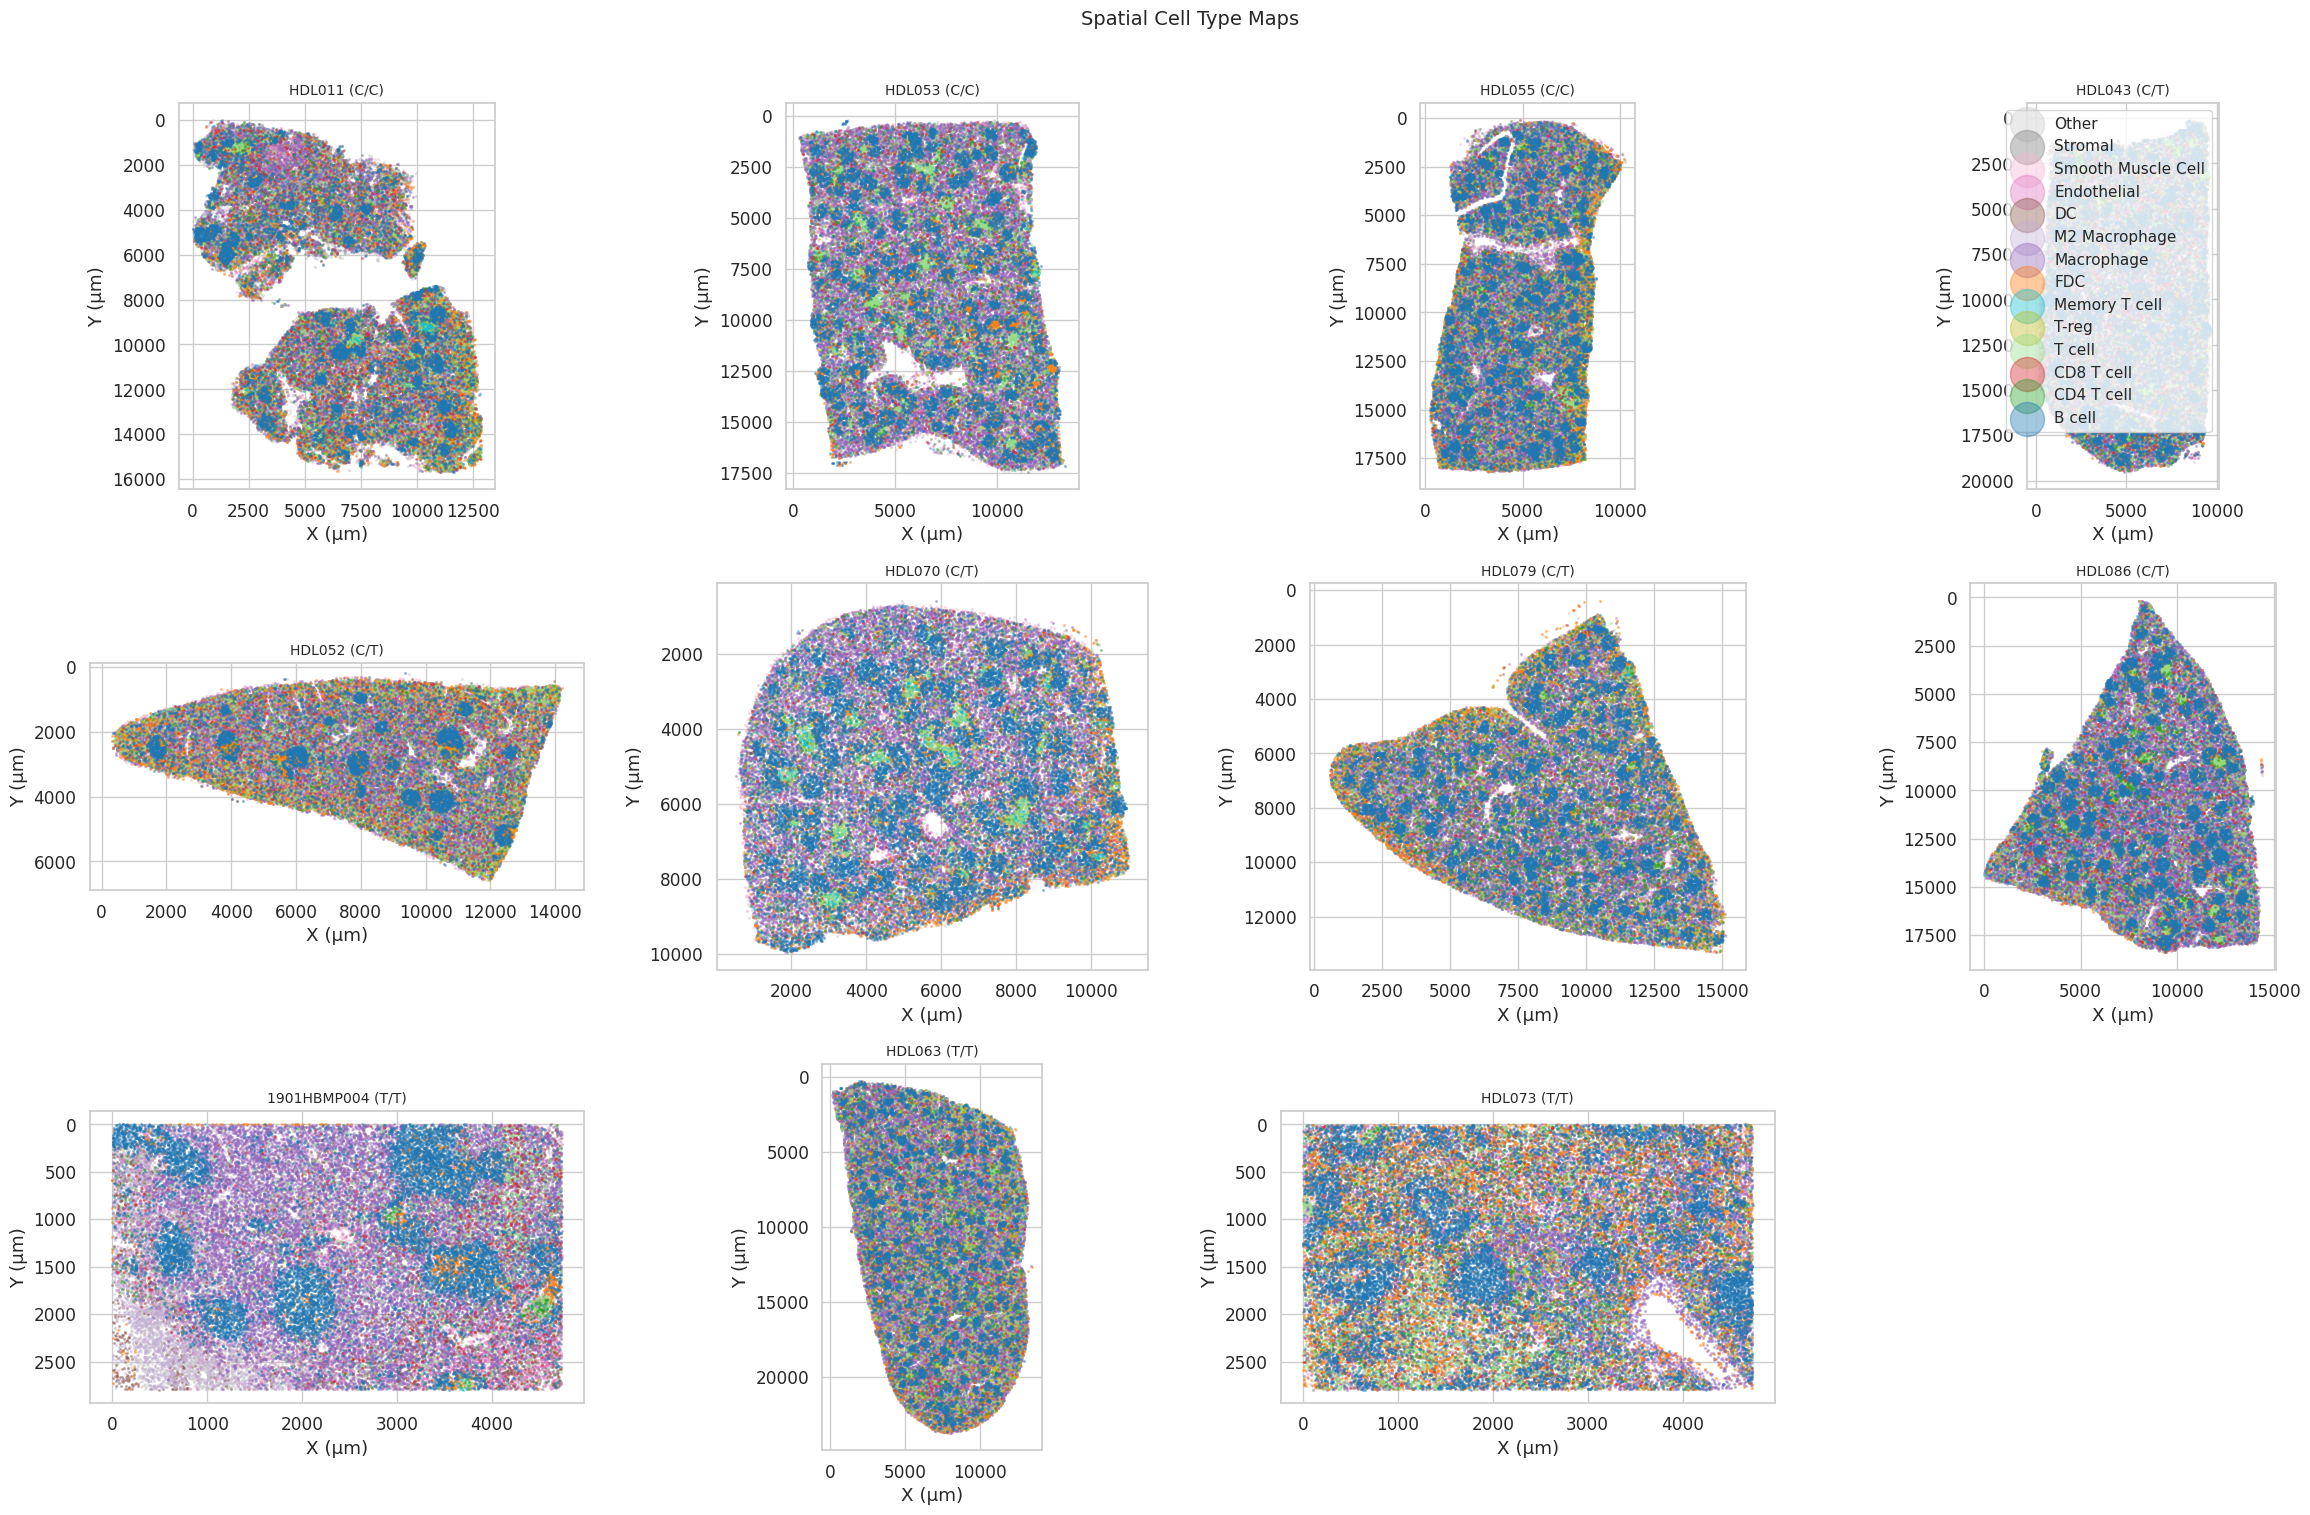

In [30]:
# ── Spatial cell type maps ──
obs_geno = adata.obs[adata.obs["Genotype"].notna()].copy()

# All samples, sorted by genotype then name
plot_samples = []
for geno in GENO_ORDER:
    geno_samples = sorted(obs_geno[obs_geno["Genotype"] == geno]["Sample"].unique())
    plot_samples.extend(geno_samples)

n_panels = len(plot_samples)
ncols = min(4, n_panels)
nrows = (n_panels + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False)

MAX_PLOT = 50_000
for i, sample in enumerate(plot_samples):
    ax = axes[i // ncols, i % ncols]
    s_data = obs_geno[obs_geno["Sample"] == sample]
    geno = s_data["Genotype"].iloc[0]

    # Subsample for plotting
    if len(s_data) > MAX_PLOT:
        rng = np.random.default_rng(42)
        idx = rng.choice(len(s_data), MAX_PLOT, replace=False)
        s_data = s_data.iloc[idx]

    for ct in reversed(CELL_TYPE_ORDER):
        mask = s_data["cell_type"].values == ct
        if not mask.any():
            continue
        ax.scatter(s_data[X_COL].values[mask], s_data[Y_COL].values[mask],
                   c=ct_palette.get(ct, "grey"), s=1.5, alpha=0.4,
                   label=ct, rasterized=True)

    ax.set_title(f"{sample} ({geno})", fontsize=10)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_xlabel("X (\u00b5m)"); ax.set_ylabel("Y (\u00b5m)")

# Legend on last used panel
axes[0, -1].legend(markerscale=20, fontsize=11, loc="upper right", frameon=True)

for j in range(n_panels, nrows * ncols):
    axes[j // ncols, j % ncols].set_visible(False)

plt.suptitle("Spatial Cell Type Maps", fontsize=14, y=1.01)
plt.tight_layout()
save_figure(fig, "H15_spatial_celltype_maps")
plt.show()

---
## Summary

### Outputs

**Figures (11):**
- `H15_umap_overview` — UMAP colored by cluster, genotype, platform, region
- `H15_cluster_marker_heatmap` — Cluster x marker mean z-score
- `H15_celltype_umap_validation` — UMAP by cell type + marker validation heatmap
- `H15_celltype_stacked_bar` — Stacked bar of proportions by sample
- `H15_celltype_genotype_boxplots` — Proportion boxplots by genotype
- `H15_region_celltype_heatmap` — Cell type fraction by tissue region
- `H15_distance_heatmap` — Mean signed distance by cell type x genotype
- `H15_neighborhood_enrichment` — Raw + log2 enrichment heatmaps
- `H15_neighborhood_genotype_boxplots` — Key neighbor pairs by genotype
- `H15_neighborhood_diversity` — Shannon entropy by genotype
- `H15_spatial_celltype_maps` — Spatial scatter plots by sample

**Tables (10):**
- `H15_cluster_marker_means` — Mean z-score per cluster per marker
- `H15_cell_type_proportions` — Per-sample cell type proportions
- `H15_celltype_genotype_stats` — KW + MW + Spearman for cell type proportions
- `H15_platform_diagnostic` — CODEX vs Phenocycler for each cell type
- `H15_region_celltype_genotype_stats` — Region-specific genotype tests
- `H15_celltype_distances` — Mean distance, fraction inside per cell type x structure
- `H15_distance_genotype_stats` — Genotype tests for key distance pairs
- `H15_neighborhood_composition` — Per-image neighborhood fractions
- `H15_neighborhood_genotype_stats` — Genotype tests for key neighbor pairs
- `H15_diversity_stats` — Shannon entropy genotype tests

In [31]:
# ── Key findings summary ──
print("=" * 60)
print("H15: Single-Cell Analysis — Summary")
print("=" * 60)
print(f"Total cells analyzed:   {adata.shape[0]:,}")
print(f"Markers:                {adata.shape[1]}")
print(f"Leiden clusters:        {adata.obs['leiden'].nunique()}")
print(f"Cell types assigned:    {adata.obs['cell_type'].nunique()}")
other_frac = (adata.obs['cell_type'] == 'Other').mean()
print(f"'Other' fraction:       {other_frac:.1%}")

# Genotype sample counts
obs_geno = adata.obs[adata.obs['Genotype'].notna()]
for g in GENO_ORDER:
    n = obs_geno[obs_geno['Genotype'] == g]['Sample'].nunique()
    print(f"  {g}: {n} samples")

# Significant associations
print("\n--- Significant Genotype Associations (p < 0.1) ---")
for tbl_name in ["H15_celltype_genotype_stats", "H15_distance_genotype_stats",
                 "H15_neighborhood_genotype_stats", "H15_diversity_stats"]:
    path = PROJECT / "analysis" / "tables" / f"{tbl_name}.csv"
    if path.exists():
        tbl = pd.read_csv(path)
        sig = tbl[tbl["p"] < 0.1]
        if len(sig):
            print(f"\n  {tbl_name}:")
            for _, r in sig.iterrows():
                print(f"    {r['Test']:30s} {r['Metric']:30s} p={r['p']:.4f}")

# Platform warnings
plat_path = PROJECT / "analysis" / "tables" / "H15_platform_diagnostic.csv"
if plat_path.exists():
    plat = pd.read_csv(plat_path)
    confounded = plat[plat["p"] < 0.1]["Feature"].tolist()
    if confounded:
        print(f"\nPlatform-confounded cell types: {confounded}")
    else:
        print("\nNo platform-confounded cell types.")

print("\nDone.")

H15: Single-Cell Analysis — Summary
Total cells analyzed:   20,782,107
Markers:                22
Leiden clusters:        35


Cell types assigned:    14
'Other' fraction:       9.0%


  C/C: 3 samples


  C/T: 5 samples


  T/T: 3 samples

--- Significant Genotype Associations (p < 0.1) ---

  H15_celltype_genotype_stats:
    Mann-Whitney (C/T vs T/T)      DC                             p=0.0714
    Spearman dosage                DC                             p=0.0830

  H15_distance_genotype_stats:
    Spearman dosage                CD8 T cell-PALS mean_dist      p=0.0830
    Spearman dosage                CD8 T cell-PALS frac_inside    p=0.0266

  H15_diversity_stats:
    Mann-Whitney (C/T vs T/T)      CD4 T cell diversity           p=0.0714
    Spearman dosage                Memory T cell diversity        p=0.0830
    Kruskal-Wallis                 DC diversity                   p=0.0305
    Mann-Whitney (C/T vs T/T)      DC diversity                   p=0.0357
    Spearman dosage                DC diversity                   p=0.0021

Platform-confounded cell types: ['T-reg', 'DC', 'Stromal']

Done.
